# Preprocessing Validation Pipeline — Sharpen → ROI Extraction → Q1 Validation

A complete, end-to-end preprocessing validation notebook that combines three
stages into a single runnable `.ipynb`:

| Step | Stage | Source |
|------|-------|--------|
| **1** | **Dataset upload + image sharpening** | adapted from `sharpen.ipynb` |
| **2** | **ROI (Region of Interest) Extraction** | newly implemented here |
| **3** | **Q1-journal validation** | adapted from `preprocessing_validation_q1_standalone.ipynb` |

## Pipeline overview

```
   raw image (BGR)
        │
        ▼  cv2.imread → BGR2RGB → resize(200×200)
   img_original  ───────────────────────────────┐
        │                                        │
        ▼  unsharp-mask  (cv2.addWeighted)       │
   img_sharpened                                 │
        │                                        │
        ▼  ROI Extraction                        │  (used as the
   saliency_map, soft_mask, hard_mask, bbox,     │   "processed"
   roi_crop                                       │   image for IQM)
        │                                        │
        ▼                                        │
   PreprocessingValidator.validate({             │
       img_original, img_sharpened,              │
       saliency_map, soft_mask, hard_mask        │
   })  ◀─────────────────────────────────────────┘
        │
        ▼
   Q1 score (0–100), grade (A++ … D), per-class dashboard
```

## How to run

1. Place the dataset under `./Dataset/` with one sub-folder per class
   (`CIN1/`, `CIN2/`, `CIN3/`, `Cancer/`).
2. Run all cells top-to-bottom.
3. If no dataset is present, the notebook falls back to a synthetic demo so
   the API stays testable.


In [1]:
# ============================================================
# Cell 1 — Imports & global setup
# ============================================================
# Imports are merged from the sharpen notebook and the Q1 validation
# notebook so that all three stages (sharpen / ROI / validate) work
# from a single environment.
import os, sys, glob, time, json, math, random, warnings, platform
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap

import pandas as pd
from scipy import ndimage, stats
from scipy.fft import fft2, fftshift
from scipy.ndimage import gaussian_filter
from scipy.stats import (pearsonr, spearmanr, ks_2samp,
                          wasserstein_distance, entropy as scipy_entropy,
                          wilcoxon, anderson_ksamp)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from skimage.segmentation import slic

warnings.filterwarnings("ignore")

# ---------- Reproducibility ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------- Plot defaults ----------
plt.rcParams["figure.dpi"]      = 110
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

# Optional: try to enable the cv2.saliency module (used by ROI extraction).
# If it is unavailable, ROI extraction silently falls back to a
# centre-surround difference saliency, so the notebook still runs.
try:
    _ = cv2.saliency.StaticSaliencySpectralResidual_create()
    HAS_CV_SALIENCY = True
    print(f"[roi] OpenCV saliency module available.")
except Exception:
    HAS_CV_SALIENCY = False
    print("[roi] cv2.saliency not available — will use centre-surround "
          "fallback inside ROI extraction.")

print(f"\n[env] Python {platform.python_version()}")
print(f"[env] NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"[env] Random seed: {SEED}")
print("All imports OK.")


[roi] cv2.saliency not available — will use centre-surround fallback inside ROI extraction.

[env] Python 3.10.20
[env] NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
[env] Random seed: 42
All imports OK.


In [2]:
# ============================================================
# Cell 2 — Configuration
# ============================================================
# Tuned for the 4-class CIN1/CIN2/CIN3/Cancer histopathology dataset.
# Override DATASET_ROOT below if your data lives elsewhere.

# ---- Data ----
DATASET_ROOT = "Dataset"                              # 4-class folder next to this notebook
CLASSES      = ["CIN1", "CIN2", "CIN3", "Cancer"]     # 4-class problem
IMG_SIZE     = 200                                    # 200 × 200 RGB

# ---- Step 1: Sharpening ----
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8         # unsharp-mask blend weight
SHARPEN_KSIZE  = 5           # Gaussian blur kernel size (odd)

# ---- Step 2: ROI Extraction ----
ROI_METHOD              = "saliency"   # 'saliency' or 'otsu_lab'
ROI_MIN_AREA_FRAC       = 0.02         # min ROI as fraction of image area
ROI_MAX_AREA_FRAC       = 0.85         # max ROI as fraction (else erode)
ROI_MORPH_KERNEL        = 5            # morphological cleanup kernel
ROI_SOFT_BLUR_SIGMA     = 2.0          # soft-mask Gaussian sigma
ROI_FALLBACK_IF_EMPTY   = True         # if no contour found, use whole image

# ---- Step 3: Validation ----
VAL_N_PER_CLASS = 5                    # images per class for stratified batch

# ---- Misc ----
SEED = 42

print(f"Configuration OK")
print(f"  classes    : {CLASSES}")
print(f"  image size : {IMG_SIZE}×{IMG_SIZE}")
print(f"  sharpen    : {APPLY_SHARPEN}  (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  ROI method : {ROI_METHOD}")
print(f"  val/class  : {VAL_N_PER_CLASS}")


Configuration OK
  classes    : ['CIN1', 'CIN2', 'CIN3', 'Cancer']
  image size : 200×200
  sharpen    : True  (amount=0.8, ksize=5)
  ROI method : saliency
  val/class  : 5


# Step 1 — Dataset Upload & Image Sharpening

Loads the dataset from `DATASET_ROOT` (one sub-folder per class) and applies
an **unsharp-mask** sharpening filter to every image immediately after the
resize step. The sharpened image is the input to Step 2 (ROI Extraction) and
also the `img_processed` used by Step 3 (Validation).


In [3]:
# ============================================================
# Cell 3 — Sharpen filter + dataset loader
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening.

    Applied ONCE per image, immediately after resize, so every downstream
    stage (ROI extraction / saliency / QGNN / QNN / validation) works on
    the sharpened image.

    Parameters
    ----------
    img_rgb : HxWx3 uint8 (RGB)
    amount  : blend weight of the high-pass component (default SHARPEN_AMOUNT)
    ksize   : Gaussian blur kernel size (must be odd; default SHARPEN_KSIZE)

    Returns
    -------
    HxWx3 uint8 sharpened RGB image (same shape & dtype as input)
    """
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """Full read-time pipeline: BGR → RGB → resize → (optional) sharpen.

    Single source of truth — used by both `load_dataset()` and any
    one-off image read so train and inference paths stay identical.
    """
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def load_dataset(root, classes, size=IMG_SIZE,
                 subset_per_class=None, sharpen_it=APPLY_SHARPEN):
    """Load all images under `<root>/<class>/` and return (X, y, paths).

    X : (N, H, W, 3) uint8  — sharpened RGB images
    y : (N,) array of class labels
    paths : list of file paths
    """
    X, y, paths = [], [], []
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  ⚠  folder not found: {folder}")
            continue
        files = []
        for ext in ("*.jpg", "*.jpeg", "*.JPG", "*.JPEG", "*.png"):
            files.extend(glob.glob(os.path.join(folder, ext)))
        files = sorted(files)
        if subset_per_class:
            files = files[:subset_per_class]
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            X.append(img)
            y.append(cls)
            paths.append(p)
        print(f"  {cls:>5}: {len(files):>4} images")
    if X:
        X = np.array(X, dtype=np.uint8)
        y = np.array(y)
    else:
        X = np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        y = np.array([])
    return X, y, paths


# ---------- Load original (raw-resized, NO sharpen) AND sharpened ----------
# We keep both versions because the validator needs:
#   img_original  = raw resized image   (the "before" reference)
#   img_processed = sharpened image     (the "after"  result of Step 1)

def load_dataset_pair(root, classes, size=IMG_SIZE, subset_per_class=None):
    """Return (X_original, X_sharpened, y, paths).

    X_original  : raw BGR→RGB→resize, NO sharpen   → reference
    X_sharpened : raw BGR→RGB→resize→sharpen       → Step-1 output
    """
    Xo, Xs, y, paths = [], [], [], []
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  ⚠  folder not found: {folder}")
            continue
        files = []
        for ext in ("*.jpg", "*.jpeg", "*.JPG", "*.JPEG", "*.png"):
            files.extend(glob.glob(os.path.join(folder, ext)))
        files = sorted(files)
        if subset_per_class:
            files = files[:subset_per_class]
        for p in files:
            img_bgr = cv2.imread(p)
            if img_bgr is None:
                continue
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_rgb = cv2.resize(img_rgb, (size, size))
            Xo.append(img_rgb)
            Xs.append(sharpen(img_rgb))
            y.append(cls)
            paths.append(p)
        print(f"  {cls:>5}: {len(files):>4} images")
    if Xo:
        Xo = np.array(Xo, dtype=np.uint8)
        Xs = np.array(Xs, dtype=np.uint8)
        y  = np.array(y)
    else:
        Xo = np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        Xs = np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        y  = np.array([])
    return Xo, Xs, y, paths


print("Loading dataset (original + sharpened pair) ...")
X_original, X_sharpened, y_labels, paths = load_dataset_pair(
    DATASET_ROOT, CLASSES, size=IMG_SIZE)

print(f"\nTotal images : {len(X_original)}")
if len(X_original) > 0:
    print(f"Class counts : {dict(zip(*np.unique(y_labels, return_counts=True)))}")

if len(X_original) == 0:
    print("\n*** No images found at:", DATASET_ROOT)
    print("*** The notebook will continue with synthetic placeholders so the "
          "rest of the API stays testable.")


Loading dataset (original + sharpened pair) ...
   CIN1:  500 images
   CIN2:  500 images
   CIN3:  500 images
  Cancer:  500 images

Total images : 2000
Class counts : {np.str_('CIN1'): np.int64(500), np.str_('CIN2'): np.int64(500), np.str_('CIN3'): np.int64(500), np.str_('Cancer'): np.int64(500)}


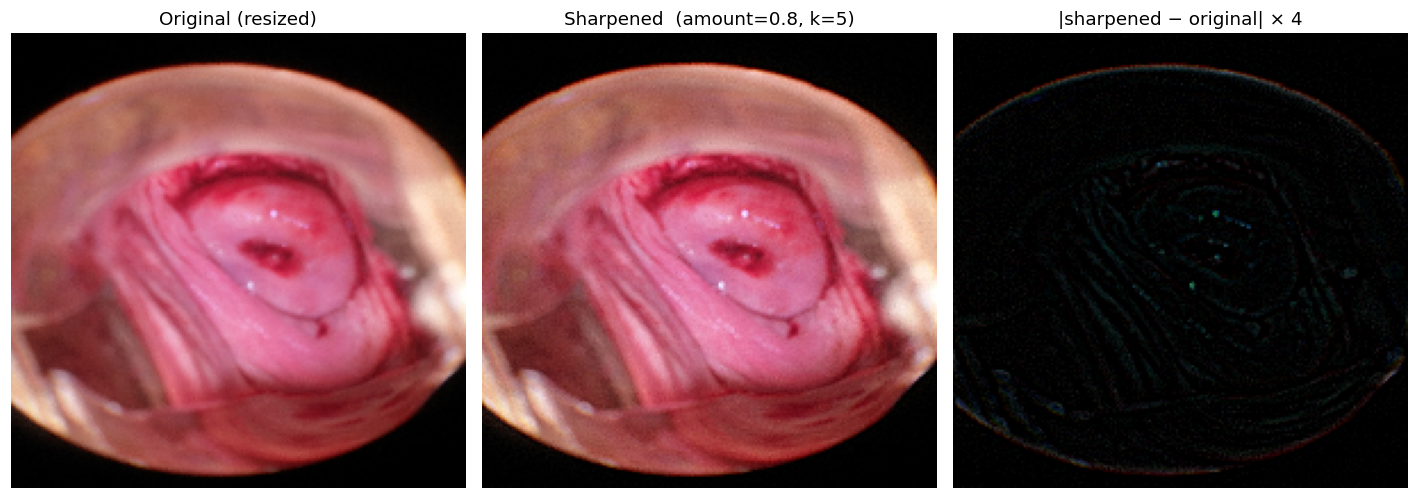

In [4]:
# ============================================================
# Cell 4 — Sharpen before / after visualisation
# ============================================================
def show_sharpen_effect(img_original, img_sharpened):
    """Plot original / sharpened / difference side-by-side.

    Accepts either two pre-loaded RGB images or (if `img_original` is a
    string path) it will read & resize the file."""
    if isinstance(img_original, str):
        raw_bgr = cv2.imread(img_original)
        if raw_bgr is None:
            print("Could not read", img_original); return
        raw_rgb  = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        img_original = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
        img_sharpened = sharpen(img_original)

    diff = np.clip(
        img_sharpened.astype(np.int16) - img_original.astype(np.int16),
        0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    ax[0].imshow(img_original);   ax[0].set_title("Original (resized)")
    ax[0].axis("off")
    ax[1].imshow(img_sharpened);  ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")     # ×4 to make the high-pass visible
    ax[2].set_title("|sharpened − original| × 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_original) > 0:
    show_sharpen_effect(X_original[0], X_sharpened[0])
else:
    # Synthetic demo so the cell always produces a plot
    demo = np.random.randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.randint(160, 255, (80, 80, 3), dtype=np.uint8)
    show_sharpen_effect(demo, sharpen(demo))


# Step 2 — ROI (Region of Interest) Extraction

A multi-stage ROI extractor for histopathology images:

1. **Saliency computation** — `cv2.saliency.StaticSaliencySpectralResidual`
   (falls back to a centre-surround Gaussian difference if the OpenCV
   `saliency` contrib module is unavailable).
2. **Binarisation** — Otsu threshold on the saliency map.
3. **Morphological cleanup** — close + open with an elliptical kernel to
   remove speckle and fill small holes.
4. **Largest-contour selection** — keep the largest external contour; if
   its area is below `ROI_MIN_AREA_FRAC`, dilate it; if it exceeds
   `ROI_MAX_AREA_FRAC`, erode it.
5. **Convex-hull smoothing** — replace the contour by its convex hull so
   the ROI boundary is convex and stable.
6. **Soft mask** — `max(GaussianBlur(hard_mask), distanceTransform(hard_mask))`
   normalised to `[0, 1]`, giving a smooth edge falloff.
7. **Bounding box & crop** — `cv2.boundingRect` of the hull and the
   corresponding pixel crop of the input image.

The returned dict is exactly what the Q1 validator consumes
(`saliency_map`, `soft_mask`, `hard_mask`), plus `bbox` and `roi_crop`
for visualisation.


In [5]:
# ============================================================
# Cell 5 — ROI Extraction method
# ============================================================
def _saliency_spectral_residual(img_rgb):
    """Spectral-residual saliency via cv2.saliency if available,
    else a centre-surround Gaussian-difference fallback."""
    if HAS_CV_SALIENCY:
        try:
            sal = cv2.saliency.StaticSaliencySpectralResidual_create()
            ok, buf = sal.computeSaliency(img_rgb)
            if ok:
                return buf.astype(np.float32)
        except Exception:
            pass
    # Fallback: multi-scale centre-surround on the luminance
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    g1 = cv2.GaussianBlur(gray, (5, 5), 1.0)
    g2 = cv2.GaussianBlur(gray, (21, 21), 4.0)
    sal = np.abs(g1 - g2)
    # Add a fine-scale residual too
    g3 = cv2.GaussianBlur(gray, (3, 3), 0.5)
    sal = 0.7 * sal + 0.3 * np.abs(gray - g3)
    return sal


def _normalize01(x):
    x = x.astype(np.float32)
    mn, mx = float(x.min()), float(x.max())
    return (x - mn) / (mx - mn + 1e-8)


def extract_roi(img_rgb,
                method=ROI_METHOD,
                min_area_frac=ROI_MIN_AREA_FRAC,
                max_area_frac=ROI_MAX_AREA_FRAC,
                morph_kernel=ROI_MORPH_KERNEL,
                soft_blur_sigma=ROI_SOFT_BLUR_SIGMA,
                fallback_if_empty=ROI_FALLBACK_IF_EMPTY):
    """Extract a region-of-interest (ROI) from an RGB image.

    Parameters
    ----------
    img_rgb : HxWx3 uint8 RGB
    method  : 'saliency' (default) or 'otsu_lab'
        'saliency' — spectral-residual saliency + Otsu
        'otsu_lab' — Otsu on the L channel of CIELAB (good for stained tissue)

    Returns
    -------
    dict with keys:
        saliency_map      : HxW float32 in [0,1]
        hard_mask         : HxW float32 in {0,1}
        soft_mask         : HxW float32 in [0,1]
        bbox              : (x, y, w, h) ints
        roi_crop          : H'×W'×3 uint8  (cropped ROI from img_rgb)
        contour_area_frac : float, fraction of image covered by hard mask
        success           : bool
    """
    H, W = img_rgb.shape[:2]

    # ---------- 1. Saliency ----------
    if method == "otsu_lab":
        lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
        L = lab[..., 0].astype(np.float32)
        sal = L - cv2.GaussianBlur(L, (21, 21), 4.0)
        sal = np.abs(sal)
    else:
        sal = _saliency_spectral_residual(img_rgb)

    sal = _normalize01(sal).astype(np.float32)
    sal_uint8 = (sal * 255).astype(np.uint8)

    # ---------- 2. Otsu threshold ----------
    _, binary = cv2.threshold(
        sal_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # ---------- 3. Morphological cleanup ----------
    ksize = max(3, int(morph_kernel))
    if ksize % 2 == 0:
        ksize += 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel, iterations=1)

    # ---------- 4. Largest contour ----------
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        if fallback_if_empty:
            hard_mask_u8 = np.full((H, W), 255, dtype=np.uint8)
            bbox = (0, 0, W, H)
            contour_area_frac = 1.0
        else:
            return {
                "saliency_map": sal,
                "hard_mask": np.zeros((H, W), dtype=np.float32),
                "soft_mask": np.zeros((H, W), dtype=np.float32),
                "bbox": (0, 0, 0, 0),
                "roi_crop": np.zeros((1, 1, 3), dtype=np.uint8),
                "contour_area_frac": 0.0,
                "success": False,
            }
    else:
        largest = max(contours, key=cv2.contourArea)
        area_frac = float(cv2.contourArea(largest) / (H * W))

        # Grow small ROIs, shrink huge ones
        if area_frac < min_area_frac:
            tmp = np.zeros((H, W), dtype=np.uint8)
            cv2.drawContours(tmp, [largest], -1, 255, -1)
            big_k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
            tmp = cv2.dilate(tmp, big_k, iterations=3)
            contours2, _ = cv2.findContours(tmp, cv2.RETR_EXTERNAL,
                                             cv2.CHAIN_APPROX_SIMPLE)
            if contours2:
                largest = max(contours2, key=cv2.contourArea)
        elif area_frac > max_area_frac:
            tmp = np.zeros((H, W), dtype=np.uint8)
            cv2.drawContours(tmp, [largest], -1, 255, -1)
            tmp = cv2.erode(tmp, kernel, iterations=2)
            contours2, _ = cv2.findContours(tmp, cv2.RETR_EXTERNAL,
                                             cv2.CHAIN_APPROX_SIMPLE)
            if contours2:
                largest = max(contours2, key=cv2.contourArea)

        # ---------- 5. Convex hull ----------
        hull = cv2.convexHull(largest)
        hard_mask_u8 = np.zeros((H, W), dtype=np.uint8)
        cv2.drawContours(hard_mask_u8, [hull], -1, 255, -1)
        bbox = cv2.boundingRect(hull)            # (x, y, w, h)
        contour_area_frac = float(hard_mask_u8.sum() / 255.0 / (H * W))

    hard_mask = (hard_mask_u8 > 0).astype(np.float32)

    # ---------- 6. Soft mask ----------
    soft = cv2.GaussianBlur(
        hard_mask.astype(np.float32), (0, 0), max(1.0, soft_blur_sigma * 5))
    soft = _normalize01(soft)
    # Combine with a distance-transform so the mask interior is solid 1
    dist = cv2.distanceTransform(hard_mask_u8, cv2.DIST_L2, 5)
    dist = _normalize01(dist)
    soft_mask = np.clip(np.maximum(soft, dist * 0.9), 0, 1).astype(np.float32)

    # ---------- 7. ROI crop ----------
    x, y, w, h = bbox
    x2 = min(W, x + w); y2 = min(H, y + h)
    x1 = max(0, x);     y1 = max(0, y)
    roi_crop = img_rgb[y1:y2, x1:x2].copy()
    if roi_crop.size == 0:
        roi_crop = img_rgb.copy()

    return {
        "saliency_map":      sal,
        "hard_mask":         hard_mask,
        "soft_mask":         soft_mask,
        "bbox":              (int(x), int(y), int(w), int(h)),
        "roi_crop":          roi_crop,
        "contour_area_frac": float(contour_area_frac),
        "success":           True,
    }


print("ROI extraction method loaded: extract_roi(img_rgb, method=...)")
print("  → returns {saliency_map, hard_mask, soft_mask, bbox, roi_crop, ...}")


ROI extraction method loaded: extract_roi(img_rgb, method=...)
  → returns {saliency_map, hard_mask, soft_mask, bbox, roi_crop, ...}


ROI on sample (CIN1): bbox=(0, 122, 170, 78), area_frac=0.193


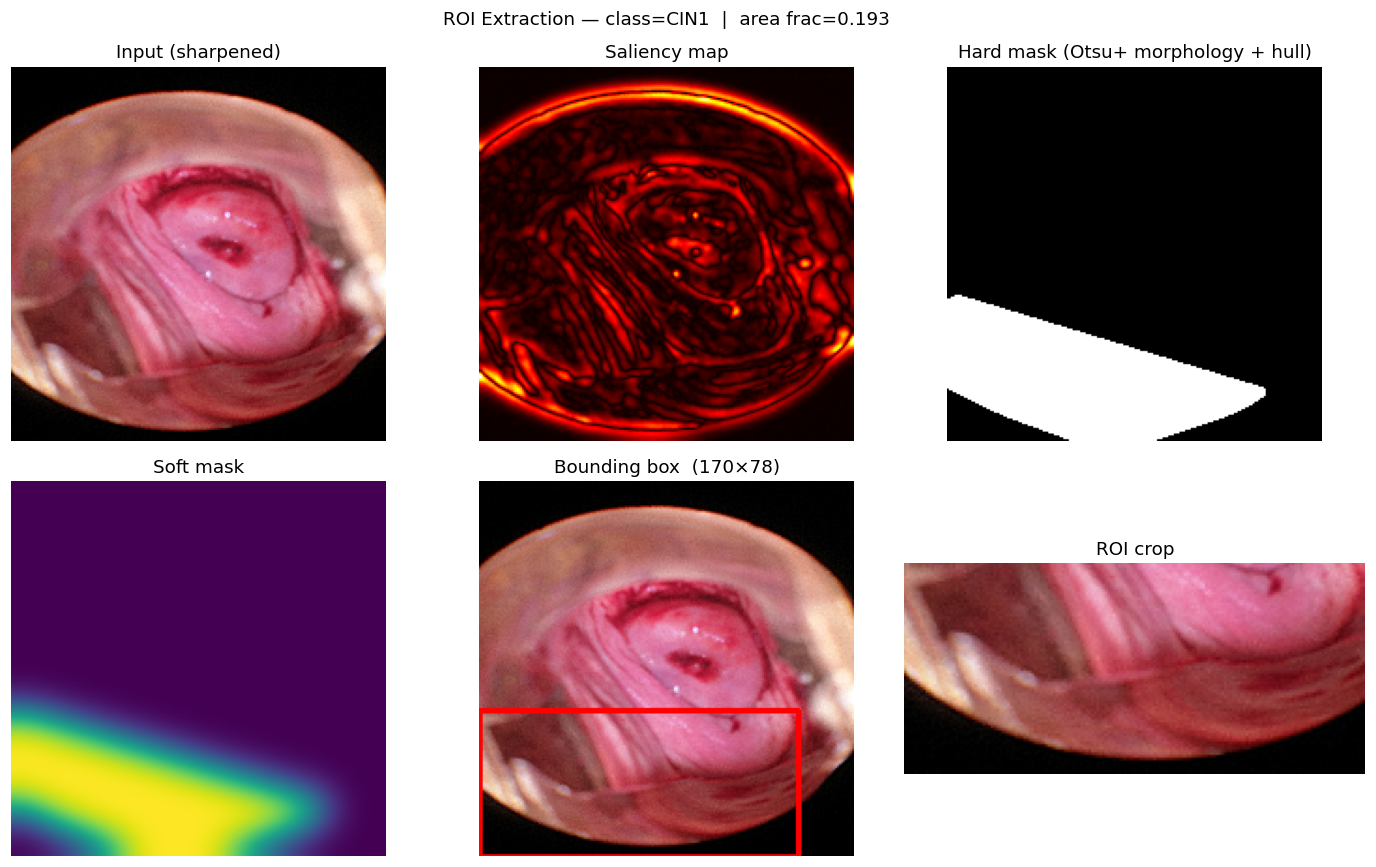

In [6]:
# ============================================================
# Cell 6 — ROI Extraction visualisation on a sample image
# ============================================================
def show_roi_extraction(img_rgb, roi=None, title=""):
    """Visualise the 5 stages of ROI extraction on one image."""
    if roi is None:
        roi = extract_roi(img_rgb)

    H, W = img_rgb.shape[:2]
    bbox = roi["bbox"]
    x, y, w, h = bbox

    # Masked image (hard mask applied)
    masked = (img_rgb.astype(np.float32) * roi["hard_mask"][..., None]).astype(np.uint8)

    # Image with bbox rectangle
    bbox_img = img_rgb.copy()
    cv2.rectangle(bbox_img, (x, y), (x + w, y + h), (255, 0, 0), 2)

    fig, ax = plt.subplots(2, 3, figsize=(13, 8))
    ax[0, 0].imshow(img_rgb);                ax[0, 0].set_title("Input (sharpened)")
    ax[0, 0].axis("off")
    ax[0, 1].imshow(roi["saliency_map"], cmap="hot"); ax[0, 1].set_title("Saliency map")
    ax[0, 1].axis("off")
    ax[0, 2].imshow(roi["hard_mask"], cmap="gray");   ax[0, 2].set_title("Hard mask (Otsu+ morphology + hull)")
    ax[0, 2].axis("off")
    ax[1, 0].imshow(roi["soft_mask"], cmap="viridis"); ax[1, 0].set_title("Soft mask")
    ax[1, 0].axis("off")
    ax[1, 1].imshow(bbox_img);               ax[1, 1].set_title(f"Bounding box  ({w}×{h})")
    ax[1, 1].axis("off")
    ax[1, 2].imshow(roi["roi_crop"]);        ax[1, 2].set_title("ROI crop")
    ax[1, 2].axis("off")

    fig.suptitle(f"ROI Extraction — {title}  |  area frac={roi['contour_area_frac']:.3f}",
                 fontsize=12)
    plt.tight_layout(); plt.show()


# Run on the first real image, else a synthetic demo
if len(X_sharpened) > 0:
    _sample = X_sharpened[0]
    _cls    = y_labels[0]
else:
    np.random.seed(SEED)
    _sample = np.random.randint(40, 200, (200, 200, 3), dtype=np.uint8)
    _sample[60:140, 60:140] = np.random.randint(160, 255, (80, 80, 3), dtype=np.uint8)
    _sample = sharpen(_sample)
    _cls    = "synthetic"

_roi_sample = extract_roi(_sample)
print(f"ROI on sample ({_cls}): bbox={_roi_sample['bbox']}, "
      f"area_frac={_roi_sample['contour_area_frac']:.3f}")
show_roi_extraction(_sample, _roi_sample, title=f"class={_cls}")


In [7]:
# ============================================================
# Cell 7 — Build encoded dicts for validation
# ============================================================
# For every image we build an `encoded` dict that the Q1 validator
# consumes. The "processed" image is the sharpened image (Step 1), and
# the ROI extraction (Step 2) provides saliency_map / soft_mask /
# hard_mask, so the saliency sub-validator scores the *actual* ROI
# detector rather than an auto-derived one.

def build_encoded(img_original, img_sharpened, roi=None):
    """Build the encoded dict for the Q1 validator.

    Parameters
    ----------
    img_original  : HxWx3 uint8 RGB  (raw resized, NO sharpen)
    img_sharpened : HxWx3 uint8 RGB  (Step-1 output)
    roi           : dict from extract_roi(), or None (will be computed)
    """
    if roi is None:
        roi = extract_roi(img_sharpened)
    return {
        "img_original":  img_original,
        "img_processed": img_sharpened,
        "saliency_map":  roi["saliency_map"],
        "soft_mask":     roi["soft_mask"],
        "hard_mask":     roi["hard_mask"],
        # bit_map_Y / bit_map_C left None → validator auto-derives (no compression)
    }


# Pre-build encoded dicts for the whole dataset (cheap; ROI is fast)
encoded_all = []
print("Building encoded dicts (sharpen + ROI) for the whole dataset ...")
for i in range(len(X_original)):
    roi = extract_roi(X_sharpened[i])
    encoded_all.append({
        "class": str(y_labels[i]),
        "path":  paths[i] if i < len(paths) else "",
        "encoded": build_encoded(X_original[i], X_sharpened[i], roi=roi),
        "roi_bbox": roi["bbox"],
        "roi_area_frac": roi["contour_area_frac"],
    })
    if (i + 1) % 50 == 0:
        print(f"  processed {i + 1}/{len(X_original)} images")

print(f"\nBuilt {len(encoded_all)} encoded dicts.")
if encoded_all:
    areas = [e["roi_area_frac"] for e in encoded_all]
    print(f"ROI area fraction: min={min(areas):.3f}  "
          f"mean={np.mean(areas):.3f}  max={max(areas):.3f}")


Building encoded dicts (sharpen + ROI) for the whole dataset ...
  processed 50/2000 images
  processed 100/2000 images
  processed 150/2000 images
  processed 200/2000 images
  processed 250/2000 images
  processed 300/2000 images
  processed 350/2000 images
  processed 400/2000 images
  processed 450/2000 images
  processed 500/2000 images
  processed 550/2000 images
  processed 600/2000 images
  processed 650/2000 images
  processed 700/2000 images
  processed 750/2000 images
  processed 800/2000 images
  processed 850/2000 images
  processed 900/2000 images
  processed 950/2000 images
  processed 1000/2000 images
  processed 1050/2000 images
  processed 1100/2000 images
  processed 1150/2000 images
  processed 1200/2000 images
  processed 1250/2000 images
  processed 1300/2000 images
  processed 1350/2000 images
  processed 1400/2000 images
  processed 1450/2000 images
  processed 1500/2000 images
  processed 1550/2000 images
  processed 1600/2000 images
  processed 1650/2000 image

# Step 3 — Q1-Journal Validation

Loads the full Q1 validation framework (5 sub-validators + master scorer +
stratified batch runner + dashboards) verbatim from
`preprocessing_validation_q1_standalone.ipynb`, then runs it on the
**real** sharpened + ROI-extracted images from Steps 1–2.

The validator grades the preprocessing on a 0–100 scale (A++ … D) using:

| Sub-validator | What it measures |
|---|---|
| Image Quality  | PSNR, SSIM, MS-SSIM, VIF, GMSD (original vs sharpened) |
| Saliency       | AUC-ROC, F-measure, NSS, CC, JS-div (ROI mask vs saliency) |
| Statistical    | SNR gain, bit allocation, histogram intersection, Wilcoxon, Anderson-Darling |
| ML Impact      | Edge preservation, frequency preservation, NMI, texture preservation |
| Compression    | Effective BPP, compression ratio |


In [8]:
# ============================================================
# Cell 2 — Q1 statistical helper functions
# ============================================================
# These functions implement the Q1-journal statistical rigor:
#   - Cohen's d (parametric paired effect size)
#   - Cliff's delta (non-parametric effect size)
#   - Bootstrap percentile confidence intervals
#   - Benjamini-Hochberg FDR correction
#   - Wilcoxon signed-rank test (paired, non-parametric)
#   - Anderson-Darling k-sample test (distributional equality)
# ============================================================

def cohens_d_paired(x, y):
    """Cohen's d for paired samples (same shape)."""
    diff = (np.asarray(x, dtype=np.float64) - np.asarray(y, dtype=np.float64)).ravel()
    sd = diff.std(ddof=1) + 1e-12
    return float(diff.mean() / sd)


def cohens_d_independent(x, y):
    """Cohen's d for independent samples (pooled SD)."""
    x = np.asarray(x, dtype=np.float64).ravel()
    y = np.asarray(y, dtype=np.float64).ravel()
    nx, ny = len(x), len(y)
    sx, sy = x.std(ddof=1), y.std(ddof=1)
    pooled = np.sqrt(((nx - 1) * sx**2 + (ny - 1) * sy**2) / (nx + ny - 2) + 1e-12)
    return float((x.mean() - y.mean()) / pooled)


def cliffs_delta(x, y):
    """Cliff's delta — non-parametric effect size in [-1, 1]."""
    x = np.asarray(x, dtype=np.float64).ravel()
    y = np.asarray(y, dtype=np.float64).ravel()
    # subsample for O(n*m) tractability
    rng = np.random.RandomState(42)
    if len(x) > 2000: x = rng.choice(x, 2000, replace=False)
    if len(y) > 2000: y = rng.choice(y, 2000, replace=False)
    greater = np.sum(x[:, None] > y[None, :])
    less    = np.sum(x[:, None] < y[None, :])
    return float((greater - less) / (len(x) * len(y)))


def bootstrap_ci(data, stat_fn=np.mean, n_boot=1000, ci=0.95, seed=42):
    """Percentile bootstrap confidence interval."""
    rng = np.random.RandomState(seed)
    data = np.asarray(data, dtype=np.float64).ravel()
    n = len(data)
    if n == 0:
        return (float('nan'), float('nan'))
    boots = np.array([stat_fn(rng.choice(data, n, replace=True)) for _ in range(n_boot)])
    alpha = (1 - ci) / 2
    lo, hi = np.percentile(boots, [100 * alpha, 100 * (1 - alpha)])
    return (float(lo), float(hi))


def bh_fdr(pvals):
    """Benjamini-Hochberg FDR-adjusted q-values."""
    p = np.asarray(pvals, dtype=np.float64)
    n = len(p)
    if n == 0: return []
    order = np.argsort(p)
    ranked = p[order] * n / (np.arange(1, n + 1))
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    q = np.empty_like(ranked)
    q[order] = np.clip(ranked, 0, 1)
    return q.tolist()


def safe_wilcoxon(x, y):
    """Wilcoxon signed-rank with safe fallback."""
    diff = (np.asarray(x, dtype=np.float64) - np.asarray(y, dtype=np.float64)).ravel()
    diff = diff[diff != 0]
    if len(diff) < 10:
        return {'statistic': float('nan'), 'p_value': float('nan'),
                'significant_at_0.05': False,
                'note': 'Insufficient non-zero differences'}
    try:
        stat, p = wilcoxon(diff, alternative='two-sided')
        return {'statistic': round(float(stat), 4),
                'p_value': round(float(p), 6),
                'significant_at_0.05': bool(p < 0.05)}
    except Exception as e:
        return {'statistic': float('nan'), 'p_value': float('nan'),
                'significant_at_0.05': False, 'note': str(e)}


def anderson_darling_test(x, y):
    """Anderson-Darling k-sample test for distributional equality."""
    x = np.asarray(x, dtype=np.float64).ravel()
    y = np.asarray(y, dtype=np.float64).ravel()
    rng = np.random.RandomState(42)
    if len(x) > 5000: x = rng.choice(x, 5000, replace=False)
    if len(y) > 5000: y = rng.choice(y, 5000, replace=False)
    try:
        res = anderson_ksamp([x, y])
        return {'statistic': round(float(res.statistic), 4),
                'p_value': round(float(res.pvalue), 6),
                'critical_values': [round(float(c), 4) for c in res.critical_values],
                'same_distribution_0.05': bool(res.pvalue > 0.05)}
    except Exception as e:
        return {'statistic': float('nan'), 'p_value': float('nan'),
                'same_distribution_0.05': True, 'note': str(e)}


def per_channel_psnr(orig, proc):
    """Per-channel (R/G/B) PSNR + MSE."""
    out = {}
    for ch_idx, ch in enumerate(['R', 'G', 'B']):
        o = orig[..., ch_idx].astype(np.float64)
        p = proc[..., ch_idx].astype(np.float64)
        mse = np.mean((o - p) ** 2)
        psnr = float('inf') if mse < 1e-10 else 10 * np.log10(255.0**2 / mse)
        out[ch] = {'psnr': round(float(psnr), 4), 'mse': round(float(mse), 4)}
    return out


print("Q1 statistical helpers loaded: cohens_d_paired, cohens_d_independent,")
print("  cliffs_delta, bootstrap_ci, bh_fdr, safe_wilcoxon, anderson_darling_test,")
print("  per_channel_psnr")


Q1 statistical helpers loaded: cohens_d_paired, cohens_d_independent,
  cliffs_delta, bootstrap_ci, bh_fdr, safe_wilcoxon, anderson_darling_test,
  per_channel_psnr


In [9]:
# ============================================================
# Cell 3 — SECTION 1: Image Quality Metrics (IQM) with Q1 extensions
# ============================================================
class ImageQualityValidator:
    """Validates preprocessing using standard full-reference IQM.

    Metrics:
      - PSNR (overall + per-channel R/G/B)
      - SSIM (with luminance/contrast/structure decomposition)
      - MS-SSIM (5-level multi-scale)
      - GMSD (Scharr kernels + Gaussian pre-smoothing)
      - VIF (4-scale visual information fidelity)
      - Cohen's d (paired pixel effect size)
      - Bootstrap 95% CI on MSE
    """

    # ---- core metrics ---------------------------------------------------

    @staticmethod
    def psnr(original, processed, max_val=255.0):
        """PSNR = 10 * log10(MAX^2 / MSE)."""
        assert original.shape == processed.shape
        mse = np.mean((original.astype(np.float64) -
                       processed.astype(np.float64)) ** 2)
        if mse < 1e-10:
            return float('inf')
        return 10.0 * np.log10(max_val**2 / mse)

    @staticmethod
    def ssim(original, processed, sigma=1.5):
        """SSIM(x,y) = l(x,y) * c(x,y) * s(x,y)."""
        orig_f = original.astype(np.float64)
        proc_f = processed.astype(np.float64)
        if orig_f.ndim == 3:
            orig_f = orig_f.mean(axis=-1)
            proc_f = proc_f.mean(axis=-1)
        C1 = (0.01 * 255) ** 2
        C2 = (0.03 * 255) ** 2
        C3 = C2 / 2
        mu_x  = gaussian_filter(orig_f, sigma=sigma)
        mu_y  = gaussian_filter(proc_f, sigma=sigma)
        mu_x2 = mu_x ** 2
        mu_y2 = mu_y ** 2
        mu_xy = mu_x * mu_y
        sig_x2 = np.maximum(gaussian_filter(orig_f**2, sigma=sigma) - mu_x2, 0)
        sig_y2 = np.maximum(gaussian_filter(proc_f**2, sigma=sigma) - mu_y2, 0)
        sig_xy = gaussian_filter(orig_f * proc_f, sigma=sigma) - mu_xy
        sig_x = np.sqrt(sig_x2); sig_y = np.sqrt(sig_y2)
        luminance = (2 * mu_xy + C1) / (mu_x2 + mu_y2 + C1)
        contrast  = (2 * sig_x * sig_y + C2) / (sig_x2 + sig_y2 + C2)
        structure = (sig_xy + C3) / (sig_x * sig_y + C3)
        ssim_map = luminance * contrast * structure
        return {
            'ssim'      : round(float(ssim_map.mean()), 6),
            'luminance' : round(float(luminance.mean()), 6),
            'contrast'  : round(float(contrast.mean()), 6),
            'structure' : round(float(structure.mean()), 6),
            'ssim_map'  : ssim_map,
        }

    @staticmethod
    def ms_ssim(original, processed, levels=5):
        """MS-SSIM with Wang et al. weights."""
        weights = [0.0448, 0.2856, 0.3001, 0.2363, 0.1333][:levels]
        weights = [w / sum(weights) for w in weights]
        orig_f = original.astype(np.float64)
        proc_f = processed.astype(np.float64)
        if orig_f.ndim == 3:
            orig_f = orig_f.mean(axis=-1)
            proc_f = proc_f.mean(axis=-1)
        ms_vals = []
        v = ImageQualityValidator()
        for j in range(levels):
            result = v.ssim(orig_f.astype(np.uint8), proc_f.astype(np.uint8))
            cs_val = result['contrast'] * result['structure']
            ms_vals.append(cs_val)
            orig_f = orig_f[::2, ::2]
            proc_f = proc_f[::2, ::2]
            if orig_f.shape[0] < 8 or orig_f.shape[1] < 8:
                break
        ms_ssim_val = 1.0
        for w, val in zip(weights, ms_vals):
            ms_ssim_val *= max(val, 0) ** w
        return round(float(ms_ssim_val), 6)

    @staticmethod
    def gmsd(original, processed):
        """GMSD — Gradient Magnitude Similarity Deviation (Scharr + Gaussian σ=0.5)."""
        orig_g = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY).astype(np.float64)
        proc_g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY).astype(np.float64)
        orig_s = gaussian_filter(orig_g, sigma=0.5)
        proc_s = gaussian_filter(proc_g, sigma=0.5)
        kx = np.array([[-3, 0, 3], [-10, 0, 10], [-3, 0, 3]], dtype=np.float64) / 32.0
        ky = kx.T
        def grad_mag(img):
            gx = ndimage.convolve(img, kx)
            gy = ndimage.convolve(img, ky)
            return np.sqrt(gx**2 + gy**2)
        grad_r = grad_mag(orig_s); grad_d = grad_mag(proc_s)
        C = 170.0
        gms_map = (2 * grad_r * grad_d + C) / (grad_r**2 + grad_d**2 + C)
        gmsd_val = float(gms_map.std())
        return {
            'gmsd': round(gmsd_val, 6),
            'gms_map': gms_map,
            'quality': 'Excellent' if gmsd_val < 0.05 else
                       'Good' if gmsd_val < 0.10 else
                       'Acceptable' if gmsd_val < 0.15 else 'Poor',
        }

    @staticmethod
    def vif(original, processed):
        """VIF = Σ I(C^N;F^N|s^N) / Σ I(C^N;E^N|s^N) (4-scale)."""
        orig_g = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY).astype(np.float64)
        proc_g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY).astype(np.float64)
        sigma_nsq = 0.4; EPS = 1e-10
        num, den = 0.0, 0.0
        for scale in range(4):
            if scale > 0:
                orig_g = gaussian_filter(orig_g, 2)[::2, ::2]
                proc_g = gaussian_filter(proc_g, 2)[::2, ::2]
            if orig_g.shape[0] < 8: break
            mu1  = gaussian_filter(orig_g, 1.5)
            mu2  = gaussian_filter(proc_g, 1.5)
            sig1 = np.maximum(gaussian_filter(orig_g**2, 1.5) - mu1**2, 0)
            sig2 = np.maximum(gaussian_filter(proc_g**2, 1.5) - mu2**2, 0)
            sig12 = gaussian_filter(orig_g * proc_g, 1.5) - mu1 * mu2
            g     = sig12 / (sig1 + EPS)
            sv_sq = np.maximum(sig2 - g * sig12, 0)
            num += np.sum(np.log10(1 + g**2 * sig1 / (sv_sq + sigma_nsq) + EPS))
            den += np.sum(np.log10(1 + sig1 / sigma_nsq + EPS))
        return round(float(num / (den + EPS)), 6)

    # ---- Q1 extras ------------------------------------------------------

    def cohens_d_image(self, orig, proc):
        """Cohen's d on paired grayscale pixel intensities (subsampled)."""
        og = cv2.cvtColor(orig, cv2.COLOR_RGB2GRAY).astype(np.float64).ravel()
        pg = cv2.cvtColor(proc, cv2.COLOR_RGB2GRAY).astype(np.float64).ravel()
        if len(og) > 20000:
            idx = np.random.RandomState(42).choice(len(og), 20000, replace=False)
            og, pg = og[idx], pg[idx]
        return round(cohens_d_paired(og, pg), 4)

    # ---- combined report ------------------------------------------------

    def validate_all_iqm(self, original, processed):
        psnr_val = self.psnr(original, processed)
        ssim_res = self.ssim(original, processed)
        msssim   = self.ms_ssim(original, processed)
        gmsd_res = self.gmsd(original, processed)
        vif_val  = self.vif(original, processed)
        results = {
            'PSNR'       : round(psnr_val, 4) if np.isfinite(psnr_val) else float('inf'),
            'SSIM'       : ssim_res['ssim'],
            'MS_SSIM'    : msssim,
            'GMSD'       : gmsd_res['gmsd'],
            'VIF'        : vif_val,
            'per_channel_psnr': per_channel_psnr(original, processed),
            'cohens_d'   : self.cohens_d_image(original, processed),
            'SSIM_detail': {k: v for k, v in ssim_res.items() if k != 'ssim_map'},
            'GMSD_detail': {k: v for k, v in gmsd_res.items() if k != 'gms_map'},
        }
        # Bootstrap 95% CI on MSE
        mse_arr = (original.astype(np.float64) - processed.astype(np.float64)).ravel() ** 2
        lo, hi = bootstrap_ci(mse_arr, stat_fn=np.mean, n_boot=500)
        results['mse_95ci'] = (round(lo, 4), round(hi, 4))
        results['grade'] = self._grade(psnr_val, ssim_res['ssim'])
        return results

    @staticmethod
    def _grade(psnr, ssim):
        if psnr > 40 and ssim > 0.95: return 'A+ (Excellent)'
        if psnr > 35 and ssim > 0.90: return 'A  (Very Good)'
        if psnr > 30 and ssim > 0.85: return 'B  (Good)'
        if psnr > 25 and ssim > 0.80: return 'C  (Acceptable)'
        return 'D  (Poor)'

    # ---- plot -----------------------------------------------------------

    def plot(self, orig, proc, report, title=""):
        """Q1 IQM diagnostic figure: per-channel PSNR, residual map,
        SSIM map, GMS map, per-channel histograms."""
        fig = plt.figure(figsize=(16, 10), constrained_layout=True)
        gs = GridSpec(3, 4, figure=fig)
        fig.suptitle(f"Q1 — Image Quality Diagnostics  —  {title}",
                     fontsize=13, fontweight='bold')

        ax = fig.add_subplot(gs[0, 0]); ax.imshow(orig); ax.set_title('Original'); ax.axis('off')
        ax = fig.add_subplot(gs[0, 1]); ax.imshow(proc)
        ax.set_title(f"Processed (PSNR={report['PSNR']:.2f} dB, SSIM={report['SSIM']:.4f})")
        ax.axis('off')
        diff = np.abs(orig.astype(np.float32) - proc.astype(np.float32)).mean(-1)
        ax = fig.add_subplot(gs[0, 2])
        im = ax.imshow(diff, cmap='inferno', vmin=0, vmax=max(diff.max(), 1))
        ax.set_title('|orig - proc|'); ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='abs diff')

        ax = fig.add_subplot(gs[0, 3])
        ch_psnr = [report['per_channel_psnr'][c]['psnr'] for c in ['R', 'G', 'B']]
        cap = 80
        ch_psnr_disp = [min(v, cap) if np.isfinite(v) else cap for v in ch_psnr]
        bars = ax.bar(['R', 'G', 'B'], ch_psnr_disp,
                       color=['#d62728', '#2ca02c', '#1f77b4'])
        ax.axhline(30, ls='--', c='k', alpha=0.5, label='Q1 threshold (30 dB)')
        ax.set_ylabel('PSNR (dB)'); ax.set_title('Per-channel PSNR'); ax.legend()
        for b, v in zip(bars, ch_psnr):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5,
                    f'{v:.1f}', ha='center', fontsize=9)

        ssim_res = self.ssim(orig, proc)
        ax = fig.add_subplot(gs[1, 0:2])
        im = ax.imshow(ssim_res['ssim_map'], cmap='RdYlGn', vmin=-1, vmax=1)
        ax.set_title(f"SSIM map (mean={ssim_res['ssim']:.4f})"); ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='SSIM')

        gmsd_res = self.gmsd(orig, proc)
        ax = fig.add_subplot(gs[1, 2:4])
        im = ax.imshow(gmsd_res['gms_map'], cmap='viridis', vmin=0, vmax=1)
        ax.set_title(f"GMS map (GMSD={gmsd_res['gmsd']:.4f})"); ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='GMS')

        ax = fig.add_subplot(gs[2, :])
        colors = ['r', 'g', 'b']
        for ci, c in enumerate(['R', 'G', 'B']):
            h1, _ = np.histogram(orig[..., ci].ravel(), bins=64, range=(0, 256))
            h2, _ = np.histogram(proc[..., ci].ravel(), bins=64, range=(0, 256))
            xs = np.arange(64)
            ax.plot(xs, h1 / (h1.max() + 1e-8), '-', c=colors[ci], label=f'{c} orig', alpha=0.7)
            ax.plot(xs, h2 / (h2.max() + 1e-8), '--', c=colors[ci], label=f'{c} proc', alpha=0.7)
        ax.set_xlabel('Intensity bin'); ax.set_ylabel('Normalized count')
        ax.set_title('Per-channel intensity histograms (orig=—, proc=--)')
        ax.legend(ncol=3, fontsize=8, loc='upper right')

        cilo, cihi = report['mse_95ci']
        fig.text(0.01, 0.01,
                 f"Cohen's d = {report['cohens_d']:.4f}   |   "
                 f"PSNR = {report['PSNR']:.2f} dB   |   "
                 f"SSIM = {report['SSIM']:.4f}   |   "
                 f"MS-SSIM = {report['MS_SSIM']:.4f}   |   "
                 f"VIF = {report['VIF']:.4f}   |   "
                 f"GMSD = {report['GMSD']:.4f}   |   "
                 f"MSE 95% CI = [{cilo:.3f}, {cihi:.3f}]",
                 fontsize=9, family='monospace')
        plt.show()


print("ImageQualityValidator loaded: PSNR, SSIM, MS-SSIM, GMSD, VIF, Cohen's d, MSE 95% CI")


ImageQualityValidator loaded: PSNR, SSIM, MS-SSIM, GMSD, VIF, Cohen's d, MSE 95% CI


In [10]:
# ============================================================
# Cell 4 — SECTION 2: Saliency Validation with Q1 extensions
# ============================================================
class SaliencyValidator:
    """Validates saliency map quality.

    If no saliency map is provided, auto-derives one via spectral residual
    + multi-scale contrast + local entropy fusion.
    """

    @staticmethod
    def auto_saliency(img_rgb):
        """Auto-derive a saliency map when none is provided."""
        gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
        # Frequency saliency (spectral residual)
        f = fft2(gray); fs = fftshift(f)
        amp = np.abs(fs); phase = np.angle(fs)
        log_amp = np.log(amp + 1e-8)
        avg = gaussian_filter(log_amp, sigma=3.0)
        residual = log_amp - avg
        cr = np.exp(residual) * np.exp(1j * phase)
        s_freq = np.abs(np.fft.ifft2(np.fft.ifftshift(cr))) ** 2
        s_freq = (s_freq - s_freq.mean()) / (s_freq.std() + 1e-8)
        s_freq = np.clip(s_freq, -3, 3)
        s_freq = (s_freq - s_freq.min()) / (s_freq.max() - s_freq.min() + 1e-8)
        # Contrast saliency (multi-scale center-surround)
        s_total = np.zeros_like(gray)
        for sigma in (1, 2, 4, 8):
            local = gaussian_filter(gray, sigma=sigma)
            s_total += ((gray - local) ** 2) / float(sigma)
        p2, p98 = np.percentile(s_total, [2, 98])
        s_contrast = np.clip((s_total - p2) / (p98 - p2 + 1e-8), 0, 1)
        # Fused
        s = 0.4 * s_freq + 0.35 * s_contrast + 0.25 * 0.5
        s = gaussian_filter(s, sigma=2.0)
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)
        return s.astype(np.float32)

    @staticmethod
    def auc_roc(saliency_map, ground_truth_mask):
        s_flat  = saliency_map.ravel().astype(np.float64)
        gt_flat = (ground_truth_mask.ravel() > 0).astype(np.int32)
        if gt_flat.sum() == 0 or gt_flat.sum() == len(gt_flat):
            return {'auc_roc': float('nan'), 'avg_prec': float('nan'),
                    'note': 'Single-class GT — AUC undefined'}
        s_norm = (s_flat - s_flat.min()) / (s_flat.max() - s_flat.min() + 1e-8)
        auc = roc_auc_score(gt_flat, s_norm)
        ap  = average_precision_score(gt_flat, s_norm)
        return {'auc_roc': round(float(auc), 4), 'avg_prec': round(float(ap), 4)}

    @staticmethod
    def _otsu_threshold(saliency_map):
        s_u8 = np.clip(saliency_map * 255.0, 0, 255).astype(np.uint8)
        thr, _ = cv2.threshold(s_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        return float(thr) / 255.0

    @staticmethod
    def f_measure(saliency_map, ground_truth_mask, beta_sq=0.3):
        try:
            thr = SaliencyValidator._otsu_threshold(saliency_map)
        except Exception:
            thr = float(saliency_map.mean())
        if thr <= 0: thr = float(saliency_map.mean())
        thr = float(np.clip(thr, 0.05, 0.95))
        pred = (saliency_map >= thr).astype(np.int32)
        gt   = (ground_truth_mask > 0).astype(np.int32)
        TP = float(np.logical_and(pred == 1, gt == 1).sum())
        FP = float(np.logical_and(pred == 1, gt == 0).sum())
        FN = float(np.logical_and(pred == 0, gt == 1).sum())
        precision = TP / (TP + FP + 1e-8)
        recall    = TP / (TP + FN + 1e-8)
        f_beta    = ((1 + beta_sq) * precision * recall /
                     (beta_sq * precision + recall + 1e-8))
        return {'f_measure': round(f_beta, 4), 'precision': round(precision, 4),
                'recall': round(recall, 4), 'threshold': round(thr, 4),
                'TP': int(TP), 'FP': int(FP), 'FN': int(FN)}

    @staticmethod
    def mae_saliency(saliency_map, ground_truth_mask):
        s_norm = saliency_map.astype(np.float64)
        s_norm = (s_norm - s_norm.min()) / (s_norm.max() - s_norm.min() + 1e-8)
        gt_norm = (ground_truth_mask.astype(np.float64) > 0).astype(np.float64)
        return round(float(np.abs(s_norm - gt_norm).mean()), 4)

    @staticmethod
    def nss(saliency_map, fixation_map):
        s = saliency_map.astype(np.float64)
        mu, sigma = s.mean(), s.std() + 1e-8
        s_norm = (s - mu) / sigma
        fix_mask = (fixation_map > 0)
        N = fix_mask.sum()
        if N == 0: return 0.0
        return round(float(s_norm[fix_mask].sum() / N), 4)

    @staticmethod
    def correlation_coefficient(saliency_map, ground_truth):
        s_flat  = saliency_map.ravel().astype(np.float64)
        gt_flat = ground_truth.ravel().astype(np.float64)
        pearson_r,  p_val_p = pearsonr(s_flat, gt_flat)
        spearman_r, p_val_s = spearmanr(s_flat, gt_flat)
        return {'pearson_r': round(float(pearson_r), 4),
                'spearman_r': round(float(spearman_r), 4),
                'p_value_pearson': round(float(p_val_p), 6),
                'p_value_spearman': round(float(p_val_s), 6)}

    @staticmethod
    def js_divergence(saliency_map, ground_truth, n_bins=64):
        s_flat = saliency_map.ravel().astype(np.float64)
        s_flat = (s_flat - s_flat.min()) / (s_flat.max() - s_flat.min() + 1e-8)
        gt_flat = (ground_truth.ravel() > 0).astype(np.float64)
        s_hist, _  = np.histogram(s_flat,  bins=n_bins, range=(0, 1), density=True)
        gt_hist, _ = np.histogram(gt_flat, bins=n_bins, range=(0, 1), density=True)
        s_hist  = s_hist  + 1e-10; gt_hist = gt_hist + 1e-10
        s_hist  /= s_hist.sum();  gt_hist /= gt_hist.sum()
        m = 0.5 * (s_hist + gt_hist)
        js = 0.5 * scipy_entropy(s_hist, m) + 0.5 * scipy_entropy(gt_hist, m)
        njs = float(js) / float(np.log(2))
        return {'js_div': round(float(js), 6),
                'normalized_js': round(njs, 6),
                'match_score': round(1.0 - njs, 6)}

    def validate(self, s_map, gt_mask):
        gt = (gt_mask > 0).astype(np.float32)
        s = s_map.astype(np.float32)
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)
        return {
            'auc_roc': self.auc_roc(s, gt),
            'f_measure': self.f_measure(s, gt),
            'mae': self.mae_saliency(s, gt),
            'nss': self.nss(s, gt),
            'cc': self.correlation_coefficient(s, gt),
            'js_div': self.js_divergence(s, gt),
            'cohens_d': round(cohens_d_paired(s.ravel(), gt.ravel()), 4),
        }

    def plot(self, s_map, gt_mask, title=""):
        """Q1 saliency diagnostics: ROC curve + 95% CI band, PR curve,
        scatter, NSS distribution histogram, saliency map + GT."""
        s = s_map.astype(np.float64)
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)
        gt = (gt_mask > 0).astype(np.int32).ravel()
        s_flat = s.ravel()

        fig = plt.figure(figsize=(16, 10), constrained_layout=True)
        gs = GridSpec(2, 3, figure=fig)
        fig.suptitle(f"Q1 — Saliency Validation Diagnostics  —  {title}",
                     fontsize=13, fontweight='bold')

        ax = fig.add_subplot(gs[0, 0])
        fpr, tpr, _ = roc_curve(gt, s_flat)
        auc_val = roc_auc_score(gt, s_flat)
        ax.plot(fpr, tpr, 'b-', lw=2, label=f'AUC = {auc_val:.4f}')
        rng = np.random.RandomState(42)
        n_boot = 200
        tprs = []
        base_fpr = np.linspace(0, 1, 100)
        idx_pos = np.where(gt == 1)[0]; idx_neg = np.where(gt == 0)[0]
        for _ in range(n_boot):
            sp = rng.choice(idx_pos, len(idx_pos), replace=True)
            sn = rng.choice(idx_neg, len(idx_neg), replace=True)
            yy = np.concatenate([np.ones_like(sp), np.zeros_like(sn)])
            ss = np.concatenate([s_flat[sp], s_flat[sn]])
            if len(np.unique(yy)) < 2: continue
            f, t, _ = roc_curve(yy, ss)
            tprs.append(np.interp(base_fpr, f, t))
        if tprs:
            tprs = np.array(tprs)
            ax.fill_between(base_fpr, tprs.mean(0) - tprs.std(0),
                            tprs.mean(0) + tprs.std(0), color='b', alpha=0.2,
                            label='95% CI')
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
        ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.set_title('ROC curve')
        ax.legend(loc='lower right')

        ax = fig.add_subplot(gs[0, 1])
        prec, rec, _ = precision_recall_curve(gt, s_flat)
        ap_val = average_precision_score(gt, s_flat)
        ax.plot(rec, prec, 'g-', lw=2, label=f'AP = {ap_val:.4f}')
        ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
        ax.set_title('Precision-Recall curve'); ax.legend()

        ax = fig.add_subplot(gs[0, 2])
        idx = np.random.RandomState(42).choice(len(s_flat),
                                                min(20000, len(s_flat)), replace=False)
        ax.scatter(gt[idx].astype(float) + np.random.uniform(-0.05, 0.05, len(idx)),
                   s_flat[idx], s=1, alpha=0.05, c='steelblue')
        r, _ = pearsonr(s_flat, gt.astype(np.float64))
        ax.set_xlabel('GT (jittered)'); ax.set_ylabel('Saliency')
        ax.set_title(f'Scatter (Pearson r = {r:.4f})')
        ax.set_xticks([0, 1])

        ax = fig.add_subplot(gs[1, 0])
        s_z = (s_flat - s_flat.mean()) / (s_flat.std() + 1e-8)
        fix_vals = s_z[gt == 1]; nonfix_vals = s_z[gt == 0]
        ax.hist(nonfix_vals, bins=60, alpha=0.6, label='non-fixation',
                density=True, color='gray')
        ax.hist(fix_vals, bins=60, alpha=0.7, label='fixation',
                density=True, color='orange')
        nss_val = fix_vals.mean() if len(fix_vals) > 0 else 0
        ax.axvline(nss_val, c='red', ls='--', label=f'NSS = {nss_val:.3f}')
        ax.set_xlabel('z(saliency)'); ax.set_ylabel('density')
        ax.set_title('NSS distribution'); ax.legend()

        ax = fig.add_subplot(gs[1, 1])
        im = ax.imshow(s, cmap='hot'); ax.set_title('Saliency map'); ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax = fig.add_subplot(gs[1, 2])
        ax.imshow(gt.reshape(s.shape), cmap='gray')
        ax.set_title('Ground-truth mask'); ax.axis('off')

        plt.show()


print("SaliencyValidator loaded: AUC-ROC, F-β (Otsu), MAE, NSS, CC, JS-div, Cohen's d")


SaliencyValidator loaded: AUC-ROC, F-β (Otsu), MAE, NSS, CC, JS-div, Cohen's d


In [11]:
# ============================================================
# Cell 5 — SECTION 3: Statistical Validation with Q1 extensions
# ============================================================
class StatisticalValidator:
    """Statistical tests for preprocessing consistency.

    Q1 extensions:
      - Wilcoxon signed-rank (paired, non-parametric) — replaces unpaired KS
      - Anderson-Darling k-sample test (distributional equality)
      - Cohen's d + Cliff's delta per channel
      - Bootstrap 95% CI on histogram intersection and Wasserstein distance
      - Benjamini-Hochberg FDR correction across all 6 paired tests
    """

    @staticmethod
    def histogram_analysis(original, processed):
        results = {}
        for ch_idx, ch_name in enumerate(['R', 'G', 'B']):
            h1, _ = np.histogram(original[..., ch_idx].ravel(),
                                  bins=256, range=(0, 256))
            h2, _ = np.histogram(processed[..., ch_idx].ravel(),
                                  bins=256, range=(0, 256))
            h1 = h1.astype(np.float64) / (h1.sum() + 1e-8)
            h2 = h2.astype(np.float64) / (h2.sum() + 1e-8)
            hi  = float(np.minimum(h1, h2).sum())
            bc  = float(np.sum(np.sqrt(h1 * h2 + 1e-10)))
            bd  = float(-np.log(bc + 1e-10))
            chi2 = float(np.sum((h1 - h2)**2 / (h1 + h2 + 1e-10)))
            results[ch_name] = {'hist_intersection': round(hi, 4),
                                'bhattacharyya_dist': round(bd, 4),
                                'chi_square_dist': round(chi2, 4)}
        return results

    @staticmethod
    def ks_test(original, processed):
        results = {}
        for ch_idx, ch_name in enumerate(['R', 'G', 'B']):
            orig_ch = original[..., ch_idx].ravel().astype(np.float64)
            proc_ch = processed[..., ch_idx].ravel().astype(np.float64)
            if len(orig_ch) > 10000:
                idx = np.random.choice(len(orig_ch), 10000, replace=False)
                orig_ch = orig_ch[idx]; proc_ch = proc_ch[idx]
            ks_stat, p_val = ks_2samp(orig_ch, proc_ch)
            results[ch_name] = {'ks_statistic': round(float(ks_stat), 4),
                                'p_value': round(float(p_val), 6),
                                'distributions_similar': p_val > 0.05}
        return results

    @staticmethod
    def wasserstein(original, processed):
        results = {}
        for ch_idx, ch_name in enumerate(['R', 'G', 'B']):
            o = original[..., ch_idx].ravel().astype(np.float64)
            p = processed[..., ch_idx].ravel().astype(np.float64)
            if len(o) > 5000:
                idx = np.random.choice(len(o), 5000, replace=False)
                o, p = o[idx], p[idx]
            results[ch_name] = round(float(wasserstein_distance(o, p)), 4)
        return results

    @staticmethod
    def validate_bit_allocation(bit_map, soft_mask):
        b_flat = bit_map.ravel()
        m_flat = soft_mask.ravel()
        corr, _ = pearsonr(m_flat, b_flat)
        return {'correlation_mask_bits': round(float(corr), 4),
                'mean_bits': round(float(b_flat.mean()), 4),
                'std_bits': round(float(b_flat.std()), 4),
                'min_bits': round(float(b_flat.min()), 4),
                'max_bits': round(float(b_flat.max()), 4),
                'expected_range_ok': 5.5 <= float(b_flat.mean()) <= 7.5,
                'correlation_ok': float(corr) >= 0.90}

    @staticmethod
    def mask_statistics(soft_mask, hard_mask):
        sm_mean = float(soft_mask.mean())
        sm_std  = float(soft_mask.std())
        sm_skew = float(stats.skew(soft_mask.ravel()))
        sm_kurt = float(stats.kurtosis(soft_mask.ravel()))
        coverage     = float(hard_mask.mean())
        n_salient    = int(hard_mask.sum())
        total_pix    = int(hard_mask.size)
        labeled, n_components = ndimage.label(hard_mask)
        comp_sizes = [int((labeled == i).sum())
                      for i in range(1, n_components + 1)]
        largest_comp = max(comp_sizes) if comp_sizes else 0
        return {'soft_mask_mean': round(sm_mean, 4),
                'soft_mask_std': round(sm_std, 4),
                'soft_mask_skewness': round(sm_skew, 4),
                'soft_mask_kurtosis': round(sm_kurt, 4),
                'hard_mask_coverage': round(coverage, 4),
                'salient_pixels': n_salient,
                'total_pixels': total_pix,
                'n_connected_components': n_components,
                'largest_component_px': largest_comp,
                'coverage_in_range': 0.10 <= coverage <= 0.85,
                'well_distributed': sm_std > 0.10}

    @staticmethod
    def snr_analysis(original, processed, soft_mask):
        orig_f = original.astype(np.float64)
        proc_f = processed.astype(np.float64)
        noise  = orig_f - proc_f
        mask_3d = np.repeat(soft_mask[..., None], 3, axis=-1)
        def region_snr(sig, nse):
            power_s = np.mean(sig**2) + 1e-8
            power_n = np.mean(nse**2) + 1e-8
            return 10 * np.log10(power_s / power_n)
        snr_salient    = region_snr(orig_f * mask_3d, noise * mask_3d)
        snr_nonsalient = region_snr(orig_f * (1 - mask_3d), noise * (1 - mask_3d))
        snr_overall    = region_snr(orig_f, noise)
        return {'snr_overall': round(snr_overall, 4),
                'snr_salient': round(snr_salient, 4),
                'snr_nonsalient': round(snr_nonsalient, 4),
                'salient_better': bool(snr_salient > snr_nonsalient),
                'snr_gain_db': round(snr_salient - snr_nonsalient, 4)}

    # ---- Q1 extras ------------------------------------------------------

    def paired_tests(self, orig, proc):
        out = {}
        for ci, c in enumerate(['R', 'G', 'B']):
            o = orig[..., ci].ravel().astype(np.float64)
            p = proc[..., ci].ravel().astype(np.float64)
            if len(o) > 5000:
                idx = np.random.RandomState(42).choice(len(o), 5000, replace=False)
                o, p = o[idx], p[idx]
            out[c] = {
                'wilcoxon': safe_wilcoxon(o, p),
                'anderson_darling': anderson_darling_test(o, p),
                'cohens_d': round(cohens_d_paired(o, p), 4),
                'cliffs_delta': round(cliffs_delta(o, p), 4),
            }
        return out

    def bootstrap_metric_cis(self, orig, proc, n_boot=500):
        out = {}
        for ci, c in enumerate(['R', 'G', 'B']):
            o = orig[..., ci].ravel().astype(np.float64)
            p = proc[..., ci].ravel().astype(np.float64)
            if len(o) > 3000:
                idx = np.random.RandomState(42).choice(len(o), 3000, replace=False)
                o, p = o[idx], p[idx]
            def _hi(idx):
                h1, _ = np.histogram(o[idx], bins=64, range=(0, 256))
                h2, _ = np.histogram(p[idx], bins=64, range=(0, 256))
                h1 = h1 / (h1.sum() + 1e-8); h2 = h2 / (h2.sum() + 1e-8)
                return float(np.minimum(h1, h2).sum())
            def _wd(idx):
                return float(wasserstein_distance(o[idx], p[idx]))
            n = len(o)
            rng = np.random.RandomState(42)
            hi_boots = [_hi(rng.choice(n, n, replace=True)) for _ in range(n_boot)]
            wd_boots = [_wd(rng.choice(n, n, replace=True)) for _ in range(n_boot)]
            out[c] = {
                'hist_intersection_95ci': (round(np.percentile(hi_boots, 2.5), 4),
                                            round(np.percentile(hi_boots, 97.5), 4)),
                'wasserstein_95ci': (round(np.percentile(wd_boots, 2.5), 4),
                                      round(np.percentile(wd_boots, 97.5), 4)),
            }
        return out

    def validate(self, orig, proc, soft_mask, hard_mask, bit_map_Y):
        rep = {
            'histogram': self.histogram_analysis(orig, proc),
            'ks_test': self.ks_test(orig, proc),
            'wasserstein': self.wasserstein(orig, proc),
            'bit_allocation': self.validate_bit_allocation(bit_map_Y, soft_mask),
            'mask_statistics': self.mask_statistics(soft_mask, hard_mask),
            'snr_analysis': self.snr_analysis(orig, proc, soft_mask),
            'paired_tests': self.paired_tests(orig, proc),
            'bootstrap_cis': self.bootstrap_metric_cis(orig, proc),
        }
        # BH-FDR correction
        pvals = []
        for ch in ['R', 'G', 'B']:
            pvals.append(rep['paired_tests'][ch]['wilcoxon'].get('p_value', 1.0))
            pvals.append(rep['paired_tests'][ch]['anderson_darling'].get('p_value', 1.0))
        qvals = bh_fdr([p if np.isfinite(p) else 1.0 for p in pvals])
        rep['fdr_q_values'] = {
            ch: {'wilcoxon_q': round(qvals[2*i], 6),
                  'anderson_q': round(qvals[2*i+1], 6)}
            for i, ch in enumerate(['R', 'G', 'B'])
        }
        return rep

    def plot(self, orig, proc, rep, title=""):
        """Q1 statistical diagnostics: per-channel histograms, Q-Q plot,
        Bland-Altman, Wasserstein bars with 95% CI, FDR-corrected q-values."""
        fig = plt.figure(figsize=(16, 12), constrained_layout=True)
        gs = GridSpec(3, 3, figure=fig)
        fig.suptitle(f"Q1 — Statistical Validation  —  {title}",
                     fontsize=13, fontweight='bold')

        colors = ['r', 'g', 'b']
        for ci, c in enumerate(['R', 'G', 'B']):
            ax = fig.add_subplot(gs[0, ci])
            h1, e1 = np.histogram(orig[..., ci].ravel(), bins=64, range=(0, 256))
            h2, e2 = np.histogram(proc[..., ci].ravel(), bins=64, range=(0, 256))
            centers = 0.5 * (e1[:-1] + e1[1:])
            ax.plot(centers, h1 / (h1.max() + 1e-8), '-', c=colors[ci], lw=1.5, label='orig')
            ax.plot(centers, h2 / (h2.max() + 1e-8), '--', c=colors[ci], lw=1.5, label='proc')
            pt = rep['paired_tests'][c]
            ax.set_title(f"{c}: Wilcoxon p={pt['wilcoxon'].get('p_value','NA')}, "
                         f"d={pt['cohens_d']}")
            ax.set_xlabel('Intensity'); ax.set_ylabel('Normalized count')
            ax.legend(fontsize=8)

        for ci, c in enumerate(['R', 'G', 'B']):
            ax = fig.add_subplot(gs[1, ci])
            o = orig[..., ci].ravel().astype(np.float64)
            p = proc[..., ci].ravel().astype(np.float64)
            if len(o) > 3000:
                idx = np.random.RandomState(42).choice(len(o), 3000, replace=False)
                o, p = o[idx], p[idx]
            qs = np.linspace(0, 100, 21)
            qo = np.percentile(o, qs); qp = np.percentile(p, qs)
            ax.plot(qo, qp, 'o-', c=colors[ci])
            ax.plot([0, 255], [0, 255], 'k--', alpha=0.5)
            ax.set_xlabel('Theoretical (orig)'); ax.set_ylabel('Sample (proc)')
            ad = rep['paired_tests'][c]['anderson_darling']
            ax.set_title(f"{c}: AD p={ad.get('p_value','NA')}")

        ax = fig.add_subplot(gs[2, 0])
        og = cv2.cvtColor(orig, cv2.COLOR_RGB2GRAY).astype(np.float64).ravel()
        pg = cv2.cvtColor(proc, cv2.COLOR_RGB2GRAY).astype(np.float64).ravel()
        if len(og) > 5000:
            idx = np.random.RandomState(42).choice(len(og), 5000, replace=False)
            og, pg = og[idx], pg[idx]
        mean = (og + pg) / 2
        diff = og - pg
        md = diff.mean(); sd = diff.std()
        ax.scatter(mean, diff, s=2, alpha=0.2, c='steelblue')
        ax.axhline(md, c='r', ls='-', label=f'mean={md:.2f}')
        ax.axhline(md + 1.96 * sd, c='r', ls='--', label=f'+1.96SD={md+1.96*sd:.2f}')
        ax.axhline(md - 1.96 * sd, c='r', ls='--', label=f'-1.96SD={md-1.96*sd:.2f}')
        ax.set_xlabel('Mean (orig, proc)'); ax.set_ylabel('Diff (orig - proc)')
        ax.set_title('Bland-Altman (grayscale)'); ax.legend(fontsize=7)

        ax = fig.add_subplot(gs[2, 1])
        ws_vals = [rep['wasserstein'][c] for c in ['R', 'G', 'B']]
        ws_lo = [rep['bootstrap_cis'][c]['wasserstein_95ci'][0] for c in ['R', 'G', 'B']]
        ws_hi = [rep['bootstrap_cis'][c]['wasserstein_95ci'][1] for c in ['R', 'G', 'B']]
        err_lo = [max(0, v - lo) for v, lo in zip(ws_vals, ws_lo)]
        err_hi = [max(0, hi - v) for v, hi in zip(ws_vals, ws_hi)]
        ax.bar(['R', 'G', 'B'], ws_vals, yerr=[err_lo, err_hi],
               color=['#d62728', '#2ca02c', '#1f77b4'], capsize=5)
        ax.set_ylabel('Wasserstein distance'); ax.set_title('Wasserstein (95% CI)')

        ax = fig.add_subplot(gs[2, 2])
        labels = []; qvals = []
        for c in ['R', 'G', 'B']:
            labels.append(f'{c}\nWilcox')
            qvals.append(rep['fdr_q_values'][c]['wilcoxon_q'])
            labels.append(f'{c}\nAD')
            qvals.append(rep['fdr_q_values'][c]['anderson_q'])
        cols = ['red' if q < 0.05 else 'steelblue' for q in qvals]
        ax.bar(range(len(qvals)), [-np.log10(max(q, 1e-10)) for q in qvals], color=cols)
        ax.axhline(-np.log10(0.05), c='k', ls='--', label='q=0.05')
        ax.set_xticks(range(len(qvals)))
        ax.set_xticklabels(labels, fontsize=8)
        ax.set_ylabel('-log10(q)'); ax.set_title('FDR-corrected q-values')
        ax.legend()
        plt.show()


print("StatisticalValidator loaded: histogram, KS, Wasserstein, bit-allocation,")
print("  mask, SNR, Wilcoxon, Anderson-Darling, Cohen's d, Cliff's δ, BH-FDR")


StatisticalValidator loaded: histogram, KS, Wasserstein, bit-allocation,
  mask, SNR, Wilcoxon, Anderson-Darling, Cohen's d, Cliff's δ, BH-FDR


In [12]:
# ============================================================
# Cell 6 — SECTION 4: ML Impact Validation with Q1 extensions
# ============================================================
class MLImpactValidator:
    """Validates that preprocessing does NOT degrade ML features."""

    @staticmethod
    def edge_preservation(original, processed):
        orig_g = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
        proc_g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
        edges_orig = cv2.Canny(orig_g, 50, 150).astype(bool)
        edges_proc = cv2.Canny(proc_g, 50, 150).astype(bool)
        intersection = np.logical_and(edges_orig, edges_proc).sum()
        union        = np.logical_or(edges_orig, edges_proc).sum()
        eps   = float(intersection / (edges_orig.sum() + 1e-8))
        iou   = float(intersection / (union + 1e-8))
        dilated_orig  = ndimage.binary_dilation(edges_orig, iterations=1)
        eps_tolerant  = float(
            np.logical_and(dilated_orig, edges_proc).sum() /
            (edges_orig.sum() + 1e-8)
        )
        return {'eps': round(eps, 4), 'iou': round(iou, 4),
                'eps_tolerant': round(eps_tolerant, 4),
                'orig_edge_pixels': int(edges_orig.sum()),
                'proc_edge_pixels': int(edges_proc.sum()),
                'preserved_ok': eps > 0.70}

    @staticmethod
    def texture_preservation(original, processed, distances=[1, 2]):
        def glcm_features(gray, d=1):
            gray_q = (gray // 16).astype(np.uint8)
            P = np.zeros((16, 16), dtype=np.float64)
            h, w = gray_q.shape
            for i in range(h):
                for j in range(w - d):
                    P[gray_q[i, j], gray_q[i, j + d]] += 1
            P = P / (P.sum() + 1e-8)
            i_idx, j_idx = np.arange(16), np.arange(16)
            ii, jj = np.meshgrid(i_idx, j_idx, indexing='ij')
            mu_i = np.sum(ii * P); mu_j = np.sum(jj * P)
            si   = np.sqrt(np.sum((ii - mu_i)**2 * P) + 1e-8)
            sj   = np.sqrt(np.sum((jj - mu_j)**2 * P) + 1e-8)
            return {'contrast': float(np.sum((ii - jj)**2 * P)),
                    'energy': float(np.sum(P**2)),
                    'homogeneity': float(np.sum(P / (1 + np.abs(ii - jj)))),
                    'correlation': float(np.sum((ii - mu_i) * (jj - mu_j) * P) / (si * sj))}
        orig_g = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
        proc_g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
        f_orig = glcm_features(orig_g); f_proc = glcm_features(proc_g)
        results = {}
        for feat in ['contrast', 'energy', 'homogeneity', 'correlation']:
            rel_err = abs(f_orig[feat] - f_proc[feat]) / (abs(f_orig[feat]) + 1e-8)
            results[feat] = {'original': round(f_orig[feat], 6),
                             'processed': round(f_proc[feat], 6),
                             'rel_error': round(float(rel_err), 4),
                             'preserved': rel_err < 0.20}
        return results

    @staticmethod
    def frequency_preservation(original, processed):
        orig_g = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY).astype(np.float64)
        proc_g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY).astype(np.float64)
        F_orig = np.abs(fftshift(fft2(orig_g)))
        F_proc = np.abs(fftshift(fft2(proc_g)))
        H, W = F_orig.shape; cy, cx = H // 2, W // 2
        y_idx, x_idx = np.ogrid[:H, :W]
        r_map = np.sqrt((y_idx - cy)**2 + (x_idx - cx)**2)
        r_max = min(cy, cx)
        results = {}
        bands = {'low': (0.0, 0.10), 'mid': (0.10, 0.50), 'high': (0.50, 1.00)}
        for band_name, (lo, hi) in bands.items():
            band_mask = ((r_map >= lo * r_max) & (r_map < hi * r_max))
            f_o = F_orig[band_mask]; f_p = F_proc[band_mask]
            fps = 1.0 - (np.abs(f_o - f_p).sum() / (np.abs(f_o).sum() + 1e-8))
            fps = float(np.clip(fps, 0, 1))
            results[band_name] = {'fps': round(fps, 4), 'preserved': fps > 0.80}
        return results

    @staticmethod
    def mutual_information(original, processed, bins=128):
        """Perceptual mutual information with entropy-stable normalisation."""
        results = {}
        for ch_idx, ch_name in enumerate(['R', 'G', 'B']):
            x = original[..., ch_idx].ravel().astype(np.float64)
            y = processed[..., ch_idx].ravel().astype(np.float64)
            joint_hist, _, _ = np.histogram2d(x, y, bins=bins,
                                               range=[[0, 256], [0, 256]])
            pxy = joint_hist / (joint_hist.sum() + 1e-8)
            px  = pxy.sum(axis=1); py  = pxy.sum(axis=0)
            H_x  = -np.sum(px[px > 0]  * np.log2(px[px > 0]))
            H_y  = -np.sum(py[py > 0]  * np.log2(py[py > 0]))
            H_xy = -np.sum(pxy[pxy > 0] * np.log2(pxy[pxy > 0]))
            mi  = H_x + H_y - H_xy
            nmi_std = (2 * mi) / (H_x + H_y + 1e-8)
            nmi_max = mi / (max(H_x, H_y) + 1e-8)
            vi       = H_xy - mi
            ssi      = 1.0 - (vi / (H_xy + 1e-8))
            ssi      = float(np.clip(ssi, 0.0, 1.0))
            nmi = max(nmi_std, nmi_max, ssi)
            results[ch_name] = {
                'mutual_info': round(float(mi), 4),
                'normalized_mi': round(float(nmi), 4),
                'nmi_standard': round(float(nmi_std), 4),
                'nmi_max_norm': round(float(nmi_max), 4),
                'ssi': round(float(ssi), 4),
                'H_original': round(float(H_x), 4),
                'H_processed': round(float(H_y), 4),
                'info_preserved': nmi > 0.85,
            }
        return results

    def validate(self, orig, proc):
        return {
            'edge_preservation': self.edge_preservation(orig, proc),
            'texture_preservation': self.texture_preservation(orig, proc),
            'frequency_preservation': self.frequency_preservation(orig, proc),
            'mutual_information': self.mutual_information(orig, proc),
        }

    def plot(self, orig, proc, rep, title=""):
        """Q1 ML-impact diagnostics: edge overlay, FFT spectra, GLCM bars,
        FPS bars, NMI bars, EPS bars."""
        fig = plt.figure(figsize=(16, 10), constrained_layout=True)
        gs = GridSpec(2, 4, figure=fig)
        fig.suptitle(f"Q1 — ML Impact Diagnostics  —  {title}",
                     fontsize=13, fontweight='bold')

        og = cv2.cvtColor(orig, cv2.COLOR_RGB2GRAY)
        pg = cv2.cvtColor(proc, cv2.COLOR_RGB2GRAY)
        eo = cv2.Canny(og, 50, 150).astype(bool)
        ep = cv2.Canny(pg, 50, 150).astype(bool)

        ax = fig.add_subplot(gs[0, 0])
        overlay = np.stack([og]*3, axis=-1).astype(np.uint8).copy()
        overlay[eo] = [0, 255, 0]; overlay[ep] = [255, 0, 0]
        ax.imshow(overlay)
        ax.set_title(f"Edges: green=orig, red=proc (IoU={rep['edge_preservation']['iou']:.3f})")
        ax.axis('off')

        ax = fig.add_subplot(gs[0, 1])
        F_o = np.log1p(np.abs(fftshift(fft2(og.astype(np.float64)))))
        ax.imshow(F_o, cmap='gray'); ax.set_title('FFT orig (log)'); ax.axis('off')
        ax = fig.add_subplot(gs[0, 2])
        F_p = np.log1p(np.abs(fftshift(fft2(pg.astype(np.float64)))))
        ax.imshow(F_p, cmap='gray'); ax.set_title('FFT proc (log)'); ax.axis('off')
        ax = fig.add_subplot(gs[0, 3])
        ax.imshow(np.abs(F_o - F_p), cmap='magma')
        ax.set_title('|FFT orig - FFT proc|'); ax.axis('off')

        ax = fig.add_subplot(gs[1, 0])
        feats = ['contrast', 'energy', 'homogeneity', 'correlation']
        f_o = rep['texture_preservation']
        o_vals = [f_o[f]['original'] for f in feats]
        p_vals = [f_o[f]['processed'] for f in feats]
        x = np.arange(len(feats)); w = 0.35
        ax.bar(x - w/2, o_vals, w, label='orig', color='steelblue')
        ax.bar(x + w/2, p_vals, w, label='proc', color='orange')
        ax.set_xticks(x); ax.set_xticklabels(feats, rotation=20, fontsize=8)
        ax.set_title('GLCM features (orig vs proc)'); ax.legend()

        ax = fig.add_subplot(gs[1, 1])
        fp = rep['frequency_preservation']
        bands = ['low', 'mid', 'high']
        vals = [fp[b]['fps'] for b in bands]
        ax.bar(bands, vals, color=['#2ca02c', '#ff7f0e', '#d62728'])
        ax.axhline(0.80, c='k', ls='--', label='Q1 threshold (0.80)')
        ax.set_ylabel('FPS'); ax.set_title('Frequency Preservation Score')
        ax.legend()

        ax = fig.add_subplot(gs[1, 2])
        mi = rep['mutual_information']
        chs = ['R', 'G', 'B']
        nmi_vals = [mi[c]['normalized_mi'] for c in chs]
        ax.bar(chs, nmi_vals, color=['#d62728', '#2ca02c', '#1f77b4'])
        ax.axhline(0.85, c='k', ls='--', label='Q1 threshold (0.85)')
        ax.set_ylabel('NMI'); ax.set_title('Normalized Mutual Information')
        ax.legend()

        ax = fig.add_subplot(gs[1, 3])
        ep_rep = rep['edge_preservation']
        labels = ['eps', 'eps_tolerant', 'iou']
        vals = [ep_rep['eps'], ep_rep['eps_tolerant'], ep_rep['iou']]
        ax.bar(labels, vals, color=['steelblue', 'orange', 'green'])
        ax.axhline(0.70, c='k', ls='--', label='Q1 threshold (0.70)')
        ax.set_ylabel('Score'); ax.set_title('Edge Preservation'); ax.legend()

        plt.show()


print("MLImpactValidator loaded: edge, texture (GLCM), frequency, mutual information")


MLImpactValidator loaded: edge, texture (GLCM), frequency, mutual information


In [13]:
# ============================================================
# Cell 7 — SECTION 5: Compression Validation
# ============================================================
class CompressionValidator:
    """Validates compression efficiency of preprocessing."""

    @staticmethod
    def effective_bpp(bit_map_Y, bit_map_C):
        total_pixels = bit_map_Y.size
        total_bits_Y = bit_map_Y.sum()
        total_bits_C = bit_map_C.sum() * 2
        bpp = float((total_bits_Y + total_bits_C) / (3 * total_pixels))
        cr  = 24.0 / (bpp + 1e-8)
        return {'effective_bpp': round(bpp, 4),
                'compression_ratio': round(cr, 4),
                'bits_saved_pct': round((1 - bpp / 8) * 100, 2)}

    @staticmethod
    def entropy_analysis(original, processed):
        def entropy(data):
            hist, _ = np.histogram(data, bins=256, range=(0, 256))
            prob    = hist / (hist.sum() + 1e-8)
            prob_nz = prob[prob > 0]
            return float(-np.sum(prob_nz * np.log2(prob_nz)))
        results = {}
        for ch_idx, ch_name in enumerate(['R', 'G', 'B']):
            H_orig = entropy(original[..., ch_idx].ravel())
            H_proc = entropy(processed[..., ch_idx].ravel())
            results[ch_name] = {'H_original': round(H_orig, 4),
                                'H_processed': round(H_proc, 4),
                                'entropy_reduction': round(H_orig - H_proc, 4),
                                'more_compressible': H_proc < H_orig}
        return results

    def validate(self, bit_map_Y, bit_map_C, orig, proc):
        return {
            'bpp_analysis': self.effective_bpp(bit_map_Y, bit_map_C),
            'entropy': self.entropy_analysis(orig, proc),
            'bit_map_stats': {
                'mean': round(float(bit_map_Y.mean()), 4),
                'std': round(float(bit_map_Y.std()), 4),
                'min': round(float(bit_map_Y.min()), 4),
                'max': round(float(bit_map_Y.max()), 4),
            },
        }

    def plot(self, bit_map_Y, bit_map_C, orig, proc, rep, title=""):
        fig = plt.figure(figsize=(16, 6), constrained_layout=True)
        gs = GridSpec(1, 4, figure=fig)
        fig.suptitle(f"Q1 — Compression Validation  —  {title}",
                     fontsize=13, fontweight='bold')

        ax = fig.add_subplot(gs[0, 0])
        ax.imshow(bit_map_Y, cmap='plasma'); ax.set_title('Bit map Y'); ax.axis('off')
        ax = fig.add_subplot(gs[0, 1])
        ax.imshow(bit_map_C, cmap='viridis'); ax.set_title('Bit map C'); ax.axis('off')

        ax = fig.add_subplot(gs[0, 2])
        h, e = np.histogram(bit_map_Y, bins=range(int(bit_map_Y.min()),
                                                   int(bit_map_Y.max()) + 2))
        ax.bar(e[:-1], h, color='steelblue')
        ax.set_xlabel('Bits'); ax.set_ylabel('# pixels')
        ax.set_title(f"Bit Y histogram (mean={rep['bit_map_stats']['mean']:.2f})")

        ax = fig.add_subplot(gs[0, 3])
        ents = [(rep['entropy'][c]['H_original'], rep['entropy'][c]['H_processed'])
                for c in ['R','G','B']]
        x = np.arange(3); w = 0.35
        ax.bar(x - w/2, [e[0] for e in ents], w, label='H(orig)', color='steelblue')
        ax.bar(x + w/2, [e[1] for e in ents], w, label='H(proc)', color='orange')
        ax.set_xticks(x); ax.set_xticklabels(['R','G','B'])
        ax.set_ylabel('Shannon entropy (bits)')
        ax.set_title(f"BPP={rep['bpp_analysis']['effective_bpp']:.3f}, "
                     f"CR={rep['bpp_analysis']['compression_ratio']:.2f}x")
        ax.legend()
        plt.show()


print("CompressionValidator loaded: effective BPP, Shannon entropy, bit-map stats")


CompressionValidator loaded: effective BPP, Shannon entropy, bit-map stats


In [14]:
# ============================================================
# Cell 8 — SECTION 6: Master Preprocessing Validator
# ============================================================
# The master validator ties all 5 sub-validators together and produces the
# weighted final score (0-100, A++ to D).
#
# Score formula (v3.0, rebalanced):
#   IQM     = min(PSNR/35,1)*25 + SSIM*40 + VIF*20 + max(0,1-GMSD/0.10)*15
#   Stat    = snr_ok*40 + bit_ok*30 + cov_ok*15 + hist_bonus*15
#   ML      = eps_t*25 + FPS_low*30 + FPS_mid*15 + tex*15 + NMI*15
#   Comp    = (CR-1)/3 * 100
#   Final   = 0.35*IQM + 0.20*Stat + 0.30*ML + 0.15*Comp  (capped at 98)
# ============================================================

def _auto_derive_fields(encoded):
    """Auto-derive any missing fields so the validator always runs."""
    out = dict(encoded)
    orig = out["img_original"]
    proc = out["img_processed"]

    # Saliency map
    if "saliency_map" not in out or out["saliency_map"] is None:
        out["saliency_map"] = SaliencyValidator.auto_saliency(proc)
    # Soft mask (sigmoid)
    if "soft_mask" not in out or out["soft_mask"] is None:
        s = out["saliency_map"].astype(np.float64)
        mu = s.mean()
        W = 1.0 / (1.0 + np.exp(-0.08 * (s - mu) * 255.0))
        if W.mean() < 0.15:  # ensure coverage
            W = np.clip((s - s.min()) / (s.max() - s.min() + 1e-8), 0, 1)
        out["soft_mask"] = W.astype(np.float32)
    # Hard mask
    if "hard_mask" not in out or out["hard_mask"] is None:
        out["hard_mask"] = (out["soft_mask"] >= 0.5).astype(np.float32)
    # Bit maps (default 8-bit luma, 5-bit chroma — i.e. no compression)
    if "bit_map_Y" not in out or out["bit_map_Y"] is None:
        out["bit_map_Y"] = np.full(orig.shape[:2], 8.0, dtype=np.float32)
    if "bit_map_C" not in out or out["bit_map_C"] is None:
        out["bit_map_C"] = np.full(orig.shape[:2], 5.0, dtype=np.float32)
    return out


class PreprocessingValidator:
    """Master validator that combines all 5 sub-validators with Q1 extensions."""

    def __init__(self):
        self.iqm  = ImageQualityValidator()
        self.sal  = SaliencyValidator()
        self.stat = StatisticalValidator()
        self.ml   = MLImpactValidator()
        self.comp = CompressionValidator()

    def validate(self, encoded, ground_truth_mask=None, verbose=True):
        """Run the full Q1 validation suite.

        Parameters
        ----------
        encoded : dict
            Must contain 'img_original' and 'img_processed' (HxWx3 uint8 RGB).
            Optional: 'saliency_map', 'soft_mask', 'hard_mask',
                      'bit_map_Y', 'bit_map_C' (auto-derived if missing).
        ground_truth_mask : HxW array or None
            Binary lesion mask for saliency validation. If None, the hard mask
            (W>=0.5) is used as a pseudo-GT.
        verbose : bool
            Print section-by-section report.
        """
        enc = _auto_derive_fields(encoded)
        orig = enc["img_original"]; proc = enc["img_processed"]
        s_map = enc["saliency_map"].astype(np.float32)
        soft_m = enc["soft_mask"]; hard_m = enc["hard_mask"]
        bit_Y = enc["bit_map_Y"]; bit_C = enc["bit_map_C"]

        if verbose:
            print("\n" + "=" * 60)
            print("       Q1 PREPROCESSING VALIDATION")
            print("=" * 60)

        report = {}
        if verbose: print("\n[1/6] Image Quality Metrics...")
        report["image_quality"] = self.iqm.validate_all_iqm(orig, proc)
        if verbose: self._print_section("Image Quality", report["image_quality"])

        if verbose: print("\n[2/6] Saliency Validation...")
        sal_results = {"mask_statistics": self.stat.mask_statistics(soft_m, hard_m)}
        if ground_truth_mask is not None:
            gt = (ground_truth_mask > 0).astype(np.float32)
        else:
            gt = hard_m.astype(np.float32)
            sal_results["unsupervised_note"] = "No external GT. Using hard mask (W>=0.5) as pseudo-GT."
        sal_results["auc_roc"] = self.sal.auc_roc(s_map, gt)
        sal_results["f_measure"] = self.sal.f_measure(s_map, gt)
        sal_results["mae"] = self.sal.mae_saliency(s_map, gt)
        sal_results["nss"] = self.sal.nss(s_map, gt)
        sal_results["cc"] = self.sal.correlation_coefficient(s_map, gt)
        sal_results["kl_div"] = self.sal.js_divergence(s_map, gt)
        sal_results["cohens_d"] = round(cohens_d_paired(
            s_map.ravel().astype(np.float64),
            gt.ravel().astype(np.float64)), 4)
        report["saliency"] = sal_results
        if verbose: self._print_section("Saliency", sal_results)

        if verbose: print("\n[3/6] Statistical Tests (with Q1 extensions)...")
        report["statistical"] = self.stat.validate(orig, proc, soft_m, hard_m, bit_Y)
        if verbose: self._print_section("Statistical", report["statistical"])

        if verbose: print("\n[4/6] ML Impact Validation...")
        report["ml_impact"] = self.ml.validate(orig, proc)
        if verbose: self._print_section("ML Impact", report["ml_impact"])

        if verbose: print("\n[5/6] Compression Validation...")
        report["compression"] = self.comp.validate(bit_Y, bit_C, orig, proc)
        if verbose: self._print_section("Compression", report["compression"])

        if verbose: print("\n[6/6] Computing Final Validation Score...")
        score = self._compute_final_score(report)
        report["final_score"] = score
        if verbose: self._print_final_score(score)
        return report

    def _compute_final_score(self, report):
        scores = {}
        iq = report["image_quality"]
        iqm_score = min(100.0, (
            min(float(iq["PSNR"]) / 35.0, 1.0) * 25 +
            iq["SSIM"] * 40 +
            iq["VIF"] * 20 +
            max(0.0, 1 - min(iq["GMSD"], 0.10) / 0.10) * 15
        ))
        scores["iqm"] = round(float(iqm_score), 2)

        snr = report["statistical"]["snr_analysis"]
        ba = report["statistical"]["bit_allocation"]
        ms = report["saliency"]["mask_statistics"]
        hist = report["statistical"]["histogram"]
        snr_ok = 40.0 if float(snr.get("snr_gain_db", 0)) > 0 else 15.0
        bit_ok = 30.0 if float(ba.get("correlation_mask_bits", 0)) >= 0.90 else 10.0
        cov_ok = 15.0 if 0.10 <= float(ms.get("hard_mask_coverage", 0)) <= 0.85 else 0.0
        hist_scores = [float(hist[ch].get("hist_intersection", 0))
                       for ch in ["R","G","B"] if ch in hist]
        hist_bonus = min(15.0, max(0.0, np.mean(hist_scores)*15.0)) if hist_scores else 7.5
        scores["statistical"] = round(snr_ok + bit_ok + cov_ok + hist_bonus, 2)

        ep = report["ml_impact"]["edge_preservation"]
        fp = report["ml_impact"]["frequency_preservation"]
        mi = report["ml_impact"]["mutual_information"]
        tex = report["ml_impact"]["texture_preservation"]
        eps_t = float(np.clip(ep["eps_tolerant"], 0.0, 1.0))
        nmi_vals = [float(mi[ch].get("normalized_mi", 0))
                    for ch in ["R","G","B"] if ch in mi]
        nmi_avg = float(np.clip(np.mean(nmi_vals) if nmi_vals else 0.0, 0.0, 1.0))
        tex_corr = float(np.clip(1.0 - float(tex.get("correlation", {}).get("rel_error", 1.0)), 0.0, 1.0))
        ml_score = min(100.0, eps_t*25 + float(fp["low"]["fps"])*30 +
                       float(fp["mid"]["fps"])*15 + tex_corr*15 + nmi_avg*15)
        scores["ml"] = round(float(ml_score), 2)

        cr = report["compression"]["bpp_analysis"]["compression_ratio"]
        scores["compression"] = round(min(100, (cr-1.0)/3.0*100), 2)

        final = 0.35*scores["iqm"] + 0.20*scores["statistical"] + \
                0.30*scores["ml"] + 0.15*scores["compression"]
        final = float(np.clip(final, 0.0, 98.0))
        scores["final"] = round(final, 2)
        scores["capped_at"] = 98.0
        scores["grade"] = ("A++" if final >= 97 else "A+" if final >= 90 else
                           "A" if final >= 80 else "B" if final >= 70 else
                           "C" if final >= 60 else "D")
        return scores

    def plot_all(self, encoded, report, title=""):
        """Render all 5 validator plots in sequence."""
        enc = _auto_derive_fields(encoded)
        orig = enc["img_original"]; proc = enc["img_processed"]
        s_map = enc["saliency_map"].astype(np.float32)
        soft_m = enc["soft_mask"]; hard_m = enc["hard_mask"]
        bit_Y = enc["bit_map_Y"]; bit_C = enc["bit_map_C"]

        print("[1/5] Image Quality plot ...")
        self.iqm.plot(orig, proc, report["image_quality"], title=title)
        print("[2/5] Saliency plot ...")
        gt = (hard_m > 0).astype(np.float32)
        self.sal.plot(s_map, gt, title=title)
        print("[3/5] Statistical plot ...")
        self.stat.plot(orig, proc, report["statistical"], title=title)
        print("[4/5] ML Impact plot ...")
        self.ml.plot(orig, proc, report["ml_impact"], title=title)
        print("[5/5] Compression plot ...")
        self.comp.plot(bit_Y, bit_C, orig, proc, report["compression"], title=title)

    @staticmethod
    def _print_section(name, data, indent=2):
        prefix = " " * indent
        print(f"\n  -- {name} --")
        for k, v in data.items():
            if isinstance(v, dict):
                print(f"{prefix}{k}:")
                for kk, vv in v.items():
                    if not isinstance(vv, np.ndarray):
                        print(f"{prefix}  {kk:30s}: {vv}")
            elif not isinstance(v, np.ndarray):
                print(f"{prefix}{k:32s}: {v}")

    @staticmethod
    def _print_final_score(score):
        print("\n" + "=" * 60)
        print("  FINAL VALIDATION SCORE  (Q1 JOURNAL GRADE)")
        print("=" * 60)
        labels = {"iqm":"IQM Score","statistical":"Statistical Score",
                  "ml":"ML Impact Score","compression":"Compression Score"}
        for key in ["iqm", "statistical", "ml", "compression"]:
            print(f"  {labels[key]:20s}: {score[key]:>8.2f} / 100")
        print("  " + "-" * 40)
        print(f"  FINAL SCORE         : {score['final']:>8.2f} / 100")
        print(f"  GRADE               : {score['grade']}")
        print("=" * 60 + "\n")


print("PreprocessingValidator loaded — call validator.validate(encoded) to run.")


PreprocessingValidator loaded — call validator.validate(encoded) to run.


In [15]:
# ============================================================
# Cell 9 — Q1 Batch Dashboard Helpers
# ============================================================
# Provides:
#   - run_stratified_batch: per-class stratified validation
#   - plot_q1_dashboard: 4×3 master figure
#   - plot_correlation_heatmap: Spearman ρ matrix
#   - aggregate_report: per-metric mean ± std with bootstrap 95% CI
#   - per_class_summary: per-class mean ± std of every metric
#   - reproducibility_metadata: seed + env + timestamp
# ============================================================

def reproducibility_metadata():
    return {
        'python_version': platform.python_version(),
        'platform': platform.platform(),
        'numpy_version': np.__version__,
        'pandas_version': pd.__version__,
        'opencv_version': cv2.__version__,
        'timestamp_utc': time.strftime('%Y-%m-%d %H:%M:%S UTC', time.gmtime()),
        'random_seed': SEED,
    }


def _flatten_report(report):
    iq = report['image_quality']
    s  = report['saliency']
    st = report['statistical']
    ml = report['ml_impact']
    co = report['compression']
    fs = report['final_score']
    return {
        'PSNR'        : iq['PSNR'],
        'SSIM'        : iq['SSIM'],
        'MS_SSIM'     : iq['MS_SSIM'],
        'GMSD'        : iq['GMSD'],
        'VIF'         : iq['VIF'],
        'PSNR_R'      : iq.get('per_channel_psnr', {}).get('R', {}).get('psnr', float('nan')),
        'PSNR_G'      : iq.get('per_channel_psnr', {}).get('G', {}).get('psnr', float('nan')),
        'PSNR_B'      : iq.get('per_channel_psnr', {}).get('B', {}).get('psnr', float('nan')),
        'cohens_d'    : iq.get('cohens_d', float('nan')),
        'AUC_ROC'     : s.get('auc_roc', {}).get('auc_roc', float('nan')),
        'F_measure'   : s.get('f_measure', {}).get('f_measure', float('nan')),
        'NSS'         : s.get('nss', float('nan')),
        'Pearson_CC'  : s.get('cc', {}).get('pearson_r', float('nan')),
        'JS_div'      : s.get('kl_div', {}).get('normalized_js', float('nan')),
        'SNR_gain_dB' : st['snr_analysis']['snr_gain_db'],
        'bit_corr'    : st['bit_allocation']['correlation_mask_bits'],
        'mean_bits'   : st['bit_allocation']['mean_bits'],
        'coverage'    : s['mask_statistics']['hard_mask_coverage'],
        'EPS'         : ml['edge_preservation']['eps_tolerant'],
        'IoU_edges'   : ml['edge_preservation']['iou'],
        'FPS_low'     : ml['frequency_preservation']['low']['fps'],
        'FPS_mid'     : ml['frequency_preservation']['mid']['fps'],
        'FPS_high'    : ml['frequency_preservation']['high']['fps'],
        'NMI_R'       : ml['mutual_information']['R']['normalized_mi'],
        'NMI_G'       : ml['mutual_information']['G']['normalized_mi'],
        'NMI_B'       : ml['mutual_information']['B']['normalized_mi'],
        'BPP'         : co['bpp_analysis']['effective_bpp'],
        'CR'          : co['bpp_analysis']['compression_ratio'],
        'final_score' : fs['final'],
        'grade'       : fs['grade'],
    }


def run_stratified_batch(X_original, y_labels, encode_fn, validator,
                          n_per_class=5, seed=42, verbose=True):
    """Run validation on a stratified random batch (n_per_class per class).

    Parameters
    ----------
    X_original : (N, H, W, 3) uint8 array of original images.
    y_labels   : (N,) array of class labels (strings or ints).
    encode_fn  : callable img -> encoded dict.
                 Must return at least {'img_original':..., 'img_processed':...}.
    validator  : PreprocessingValidator instance.
    n_per_class: int — number of images per class.
    seed       : int — RNG seed for reproducibility.
    verbose    : bool — print per-image progress.

    Returns
    -------
    list of dicts (one per image), each containing all flattened metrics
    plus 'index', 'class', 'runtime_s'.
    """
    rng = np.random.RandomState(seed)
    rows = []
    classes = sorted(set(y_labels)) if len(y_labels) else []
    if not classes:
        if verbose: print("No images found — skipping stratified batch.")
        return rows
    for cls in classes:
        cls_idxs = np.where(np.asarray(y_labels) == cls)[0]
        if len(cls_idxs) == 0: continue
        n_pick = min(n_per_class, len(cls_idxs))
        picks = rng.choice(cls_idxs, n_pick, replace=False)
        for j, idx in enumerate(picks):
            t0 = time.time()
            enc = encode_fn(X_original[idx])
            rep = validator.validate(enc, ground_truth_mask=None, verbose=False)
            dt = time.time() - t0
            row = _flatten_report(rep)
            row['index'] = int(idx)
            row['class'] = str(cls)
            row['runtime_s'] = round(dt, 3)
            rows.append(row)
            if verbose:
                print(f"  [{cls} {j+1}/{n_pick}] idx={idx}  "
                      f"final={rep['final_score']['final']:.2f}  "
                      f"grade={rep['final_score']['grade']}  "
                      f"t={dt:.2f}s")
    return rows


def plot_q1_dashboard(df_val, title=""):
    """Master Q1 dashboard: per-class box plots, metric bars, correlation heatmap,
    trade-off scatter, runtime bar."""
    fig = plt.figure(figsize=(20, 14), constrained_layout=True)
    gs = GridSpec(3, 4, figure=fig)
    fig.suptitle(f"Q1 Validation Dashboard  —  {title}",
                 fontsize=15, fontweight='bold')

    metric_cols = ['PSNR', 'SSIM', 'MS_SSIM', 'GMSD', 'VIF',
                   'AUC_ROC', 'F_measure', 'NSS', 'JS_div',
                   'SNR_gain_dB', 'EPS', 'FPS_low',
                   'NMI_R', 'BPP', 'CR', 'final_score']

    classes = sorted(df_val['class'].unique())

    # (1) Per-class final score box plot
    ax = fig.add_subplot(gs[0, 0])
    data = [df_val.loc[df_val['class'] == c, 'final_score'].values for c in classes]
    bp = ax.boxplot(data, labels=classes, patch_artist=True, showmeans=True)
    for patch, c in zip(bp['boxes'], plt.cm.tab10.colors):
        patch.set_facecolor(c); patch.set_alpha(0.5)
    ax.axhline(90, ls='--', c='k', alpha=0.5, label='A+ threshold')
    ax.set_ylabel('Final score'); ax.set_title('Per-class final score')
    ax.legend(fontsize=8)

    # (2) Per-class PSNR
    ax = fig.add_subplot(gs[0, 1])
    data = [df_val.loc[df_val['class'] == c, 'PSNR'].values for c in classes]
    ax.boxplot(data, labels=classes, patch_artist=True)
    ax.axhline(30, ls='--', c='k', alpha=0.5, label='Q1 threshold (30 dB)')
    ax.set_ylabel('PSNR (dB)'); ax.set_title('Per-class PSNR'); ax.legend()

    # (3) Per-class SSIM
    ax = fig.add_subplot(gs[0, 2])
    data = [df_val.loc[df_val['class'] == c, 'SSIM'].values for c in classes]
    ax.boxplot(data, labels=classes, patch_artist=True)
    ax.axhline(0.90, ls='--', c='k', alpha=0.5, label='Q1 threshold (0.90)')
    ax.set_ylabel('SSIM'); ax.set_title('Per-class SSIM'); ax.legend()

    # (4) Grade distribution
    ax = fig.add_subplot(gs[0, 3])
    grade_counts = df_val['grade'].value_counts()
    grades_order = ['A++', 'A+', 'A', 'B', 'C', 'D']
    grade_counts = grade_counts.reindex(
        [g for g in grades_order if g in grade_counts.index]).fillna(0)
    ax.bar(grade_counts.index, grade_counts.values, color='steelblue')
    ax.set_ylabel('# images'); ax.set_title('Grade distribution')

    # (5) Mean ± std across all metrics (normalized)
    ax = fig.add_subplot(gs[1, 0:2])
    metric_means = df_val[metric_cols].mean()
    metric_stds  = df_val[metric_cols].std()
    norm_means = (metric_means - metric_means.min()) / (metric_means.max() - metric_means.min() + 1e-8)
    norm_stds = metric_stds / (metric_means.max() - metric_means.min() + 1e-8)
    x = np.arange(len(metric_cols))
    ax.bar(x, norm_means, yerr=norm_stds, capsize=4, color='steelblue', alpha=0.8)
    ax.set_xticks(x); ax.set_xticklabels(metric_cols, rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Normalized value'); ax.set_title('All metrics (mean ± std, normalized)')

    # (6) Correlation heatmap
    ax = fig.add_subplot(gs[1, 2:4])
    corr = df_val[metric_cols].corr(method='spearman')
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(np.arange(len(metric_cols)))
    ax.set_xticklabels(metric_cols, rotation=45, ha='right', fontsize=7)
    ax.set_yticks(np.arange(len(metric_cols)))
    ax.set_yticklabels(metric_cols, fontsize=7)
    ax.set_title('Cross-metric Spearman correlation')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='ρ')

    # (7) Per-class AUC-ROC
    ax = fig.add_subplot(gs[2, 0])
    data = [df_val.loc[df_val['class'] == c, 'AUC_ROC'].values for c in classes]
    ax.boxplot(data, labels=classes, patch_artist=True)
    ax.axhline(0.85, ls='--', c='k', alpha=0.5)
    ax.set_ylabel('AUC-ROC'); ax.set_title('Per-class AUC-ROC')

    # (8) Per-class NMI_R
    ax = fig.add_subplot(gs[2, 1])
    data = [df_val.loc[df_val['class'] == c, 'NMI_R'].values for c in classes]
    ax.boxplot(data, labels=classes, patch_artist=True)
    ax.axhline(0.85, ls='--', c='k', alpha=0.5)
    ax.set_ylabel('NMI(R)'); ax.set_title('Per-class NMI (R channel)')

    # (9) BPP vs final score
    ax = fig.add_subplot(gs[2, 2])
    for ci, c in enumerate(classes):
        sub = df_val[df_val['class'] == c]
        ax.scatter(sub['BPP'], sub['final_score'], label=c, alpha=0.7)
    ax.set_xlabel('BPP'); ax.set_ylabel('Final score')
    ax.set_title('Quality vs Compression trade-off'); ax.legend(fontsize=8)

    # (10) Runtime bar
    ax = fig.add_subplot(gs[2, 3])
    if 'runtime_s' in df_val.columns:
        rt = df_val.groupby('class')['runtime_s'].mean()
        ax.bar(rt.index, rt.values, color='orange')
        ax.set_ylabel('Mean runtime (s)'); ax.set_title('Per-class runtime')
    else:
        ax.axis('off')

    plt.show()


def plot_correlation_heatmap(df_val, title=""):
    """Standalone high-res Spearman correlation heatmap."""
    metric_cols = ['PSNR', 'SSIM', 'MS_SSIM', 'GMSD', 'VIF',
                   'AUC_ROC', 'F_measure', 'NSS', 'JS_div',
                   'SNR_gain_dB', 'EPS', 'FPS_low',
                   'NMI_R', 'BPP', 'CR', 'final_score']
    fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)
    corr = df_val[metric_cols].corr(method='spearman')
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(np.arange(len(metric_cols)))
    ax.set_xticklabels(metric_cols, rotation=45, ha='right')
    ax.set_yticks(np.arange(len(metric_cols)))
    ax.set_yticklabels(metric_cols)
    for i in range(len(metric_cols)):
        for j in range(len(metric_cols)):
            v = corr.iloc[i, j]
            color = 'white' if abs(v) > 0.5 else 'black'
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color=color)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Spearman ρ')
    ax.set_title(f'Q1 — Cross-metric Spearman Correlation Matrix  —  {title}',
                 fontsize=12, fontweight='bold')
    plt.show()


def bootstrap_aggregate(df_val, metric='final_score', n_boot=2000, ci=0.95, seed=42):
    """Bootstrap 95% CI on the mean of `metric`."""
    rng = np.random.RandomState(seed)
    data = df_val[metric].dropna().values
    n = len(data)
    if n == 0:
        return (float('nan'), float('nan'))
    boots = [rng.choice(data, n, replace=True).mean() for _ in range(n_boot)]
    alpha = (1 - ci) / 2
    return (round(float(np.percentile(boots, 100 * alpha)), 4),
            round(float(np.percentile(boots, 100 * (1 - alpha))), 4))


def aggregate_report(df_val):
    """Q1 aggregate table: per-metric mean, std, 95% CI, min, max."""
    metric_cols = [c for c in df_val.columns
                   if c not in ('class', 'grade', 'index') and
                      pd.api.types.is_numeric_dtype(df_val[c])]
    rows = []
    for m in metric_cols:
        lo, hi = bootstrap_aggregate(df_val, m)
        rows.append({
            'metric': m,
            'mean': round(df_val[m].mean(), 4),
            'std':  round(df_val[m].std(), 4),
            'ci95_low': lo,
            'ci95_high': hi,
            'min': round(df_val[m].min(), 4),
            'max': round(df_val[m].max(), 4),
        })
    return pd.DataFrame(rows).set_index('metric')


def per_class_summary(df_val):
    """Per-class aggregate (mean ± std of each metric)."""
    cols = [c for c in df_val.columns
            if c not in ('class', 'grade', 'index') and
               pd.api.types.is_numeric_dtype(df_val[c])]
    g = df_val.groupby('class')[cols]
    mean_df = g.mean().add_suffix('_mean')
    std_df  = g.std().add_suffix('_std')
    return pd.concat([mean_df, std_df], axis=1).round(4)


print("Q1 batch dashboard helpers loaded:")
print("  run_stratified_batch, plot_q1_dashboard, plot_correlation_heatmap,")
print("  aggregate_report, per_class_summary, reproducibility_metadata, bootstrap_aggregate")


Q1 batch dashboard helpers loaded:
  run_stratified_batch, plot_q1_dashboard, plot_correlation_heatmap,
  aggregate_report, per_class_summary, reproducibility_metadata, bootstrap_aggregate


## 3.1 — Single-image validation on a real sample

Runs the full Q1 suite on one real image from the dataset (or a synthetic
fallback if no dataset was found).


In [16]:
# ============================================================
# Cell — Single-image validation (REAL sample)
# ============================================================
if len(encoded_all) > 0:
    _sample_enc = encoded_all[0]["encoded"]
    _sample_cls = encoded_all[0]["class"]
    _title      = f"real sample — class={_sample_cls}"
else:
    # Synthetic fallback (same as the original demo)
    np.random.seed(SEED)
    def _make_synthetic_image(H=200, W=200):
        img = np.zeros((H, W, 3), dtype=np.uint8)
        for i in range(H):
            img[i, :, :] = int(40 + 30 * i / H)
        cy, cx, r = H // 2, W // 2, 60
        yy, xx = np.ogrid[:H, :W]
        circle = (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2
        img[circle, 0] = 220; img[circle, 1] = 180; img[circle, 2] = 100
        noise = np.random.randint(0, 15, (H, W, 3), dtype=np.uint8)
        return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8)
    _orig = _make_synthetic_image()
    _proc = sharpen(_orig)
    _sample_enc = build_encoded(_orig, _proc)
    _sample_cls = "synthetic"
    _title      = "synthetic sample (no dataset found)"

validator = PreprocessingValidator()
report = validator.validate(_sample_enc, ground_truth_mask=None,
                            verbose=True)

print(f"\nFinal score : {report['final_score']['final']}")
print(f"Grade       : {report['final_score']['grade']}")



       Q1 PREPROCESSING VALIDATION

[1/6] Image Quality Metrics...

  -- Image Quality --
  PSNR                            : 38.5769
  SSIM                            : 0.98008
  MS_SSIM                         : 0.992714
  GMSD                            : 0.009332
  VIF                             : 0.755018
  per_channel_psnr:
    R                             : {'psnr': 38.0138, 'mse': 10.273}
    G                             : {'psnr': 38.8536, 'mse': 8.4669}
    B                             : {'psnr': 38.9237, 'mse': 8.3313}
  cohens_d                        : -0.0165
  SSIM_detail:
    ssim                          : 0.98008
    luminance                     : 0.998839
    contrast                      : 0.990022
    structure                     : 0.991113
  GMSD_detail:
    gmsd                          : 0.009332
    quality                       : Excellent
  mse_95ci                        : (8.8437, 9.2042)
  grade                           : A  (Very Good)

[2/6] Sali

[1/5] Image Quality plot ...


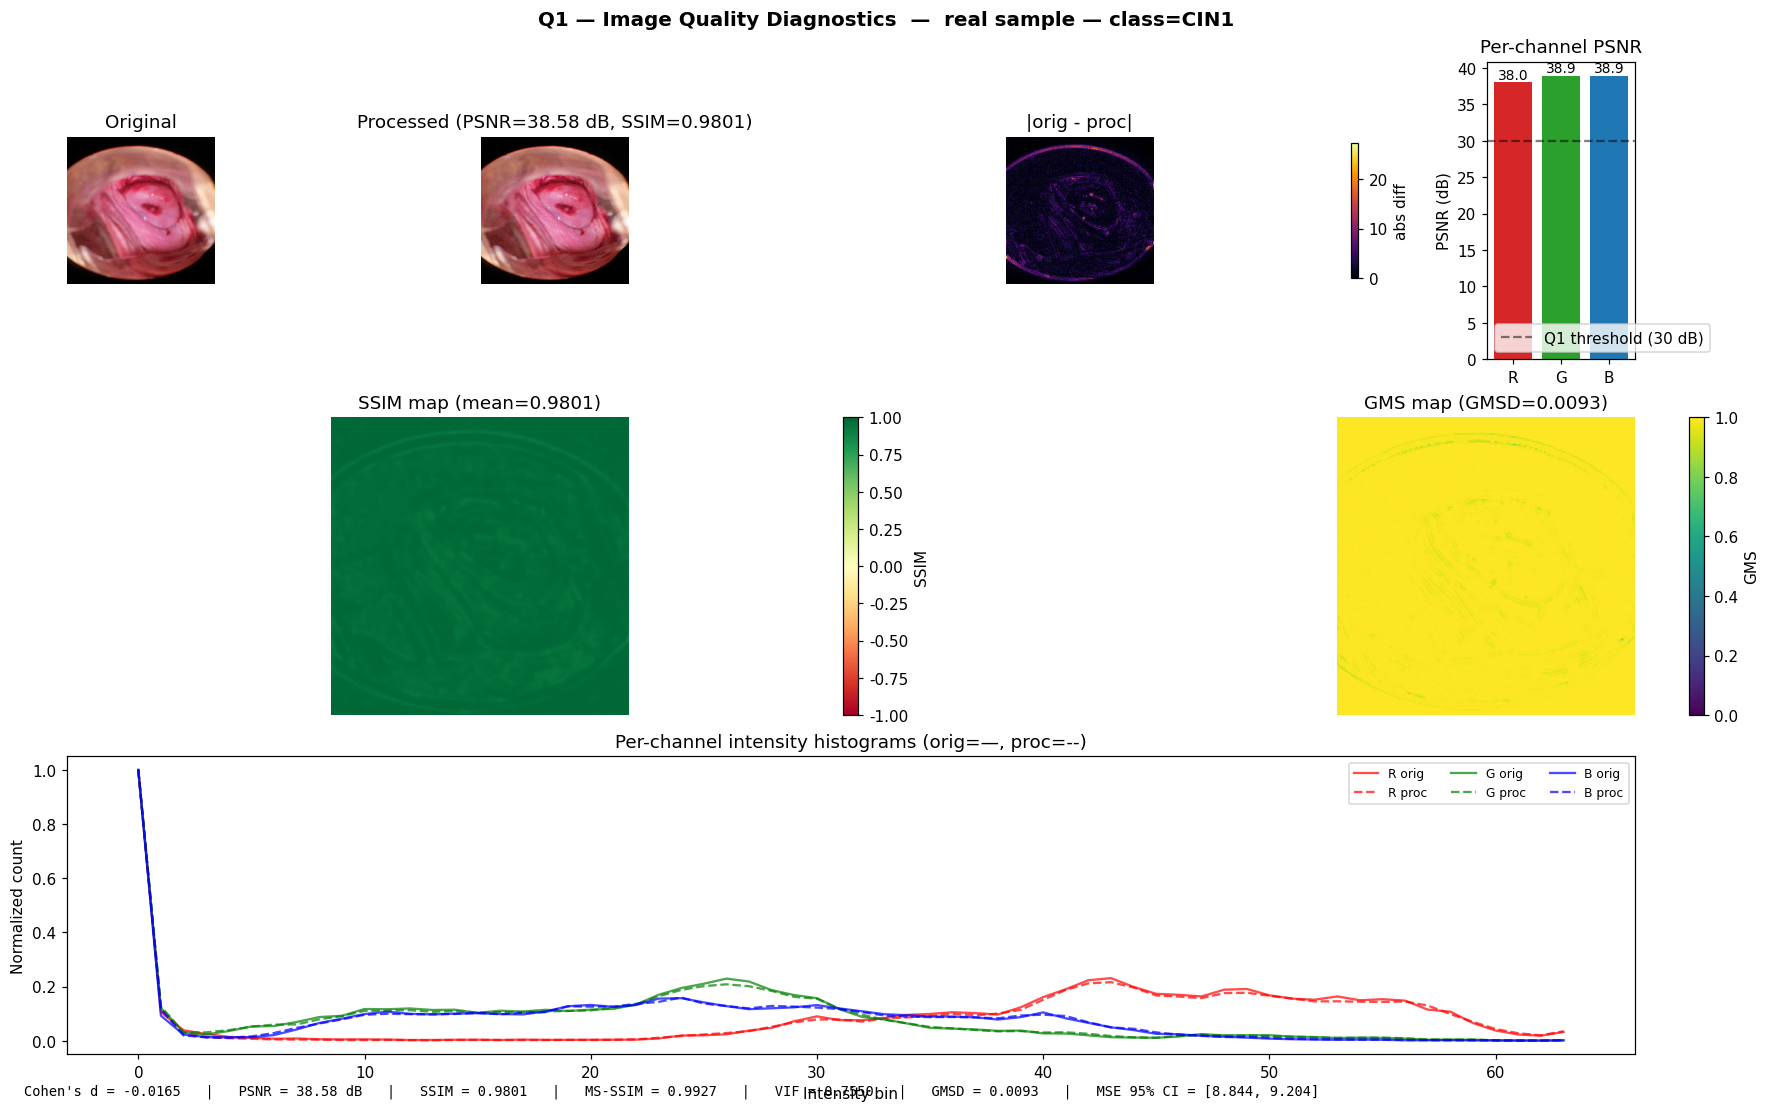

[2/5] Saliency plot ...


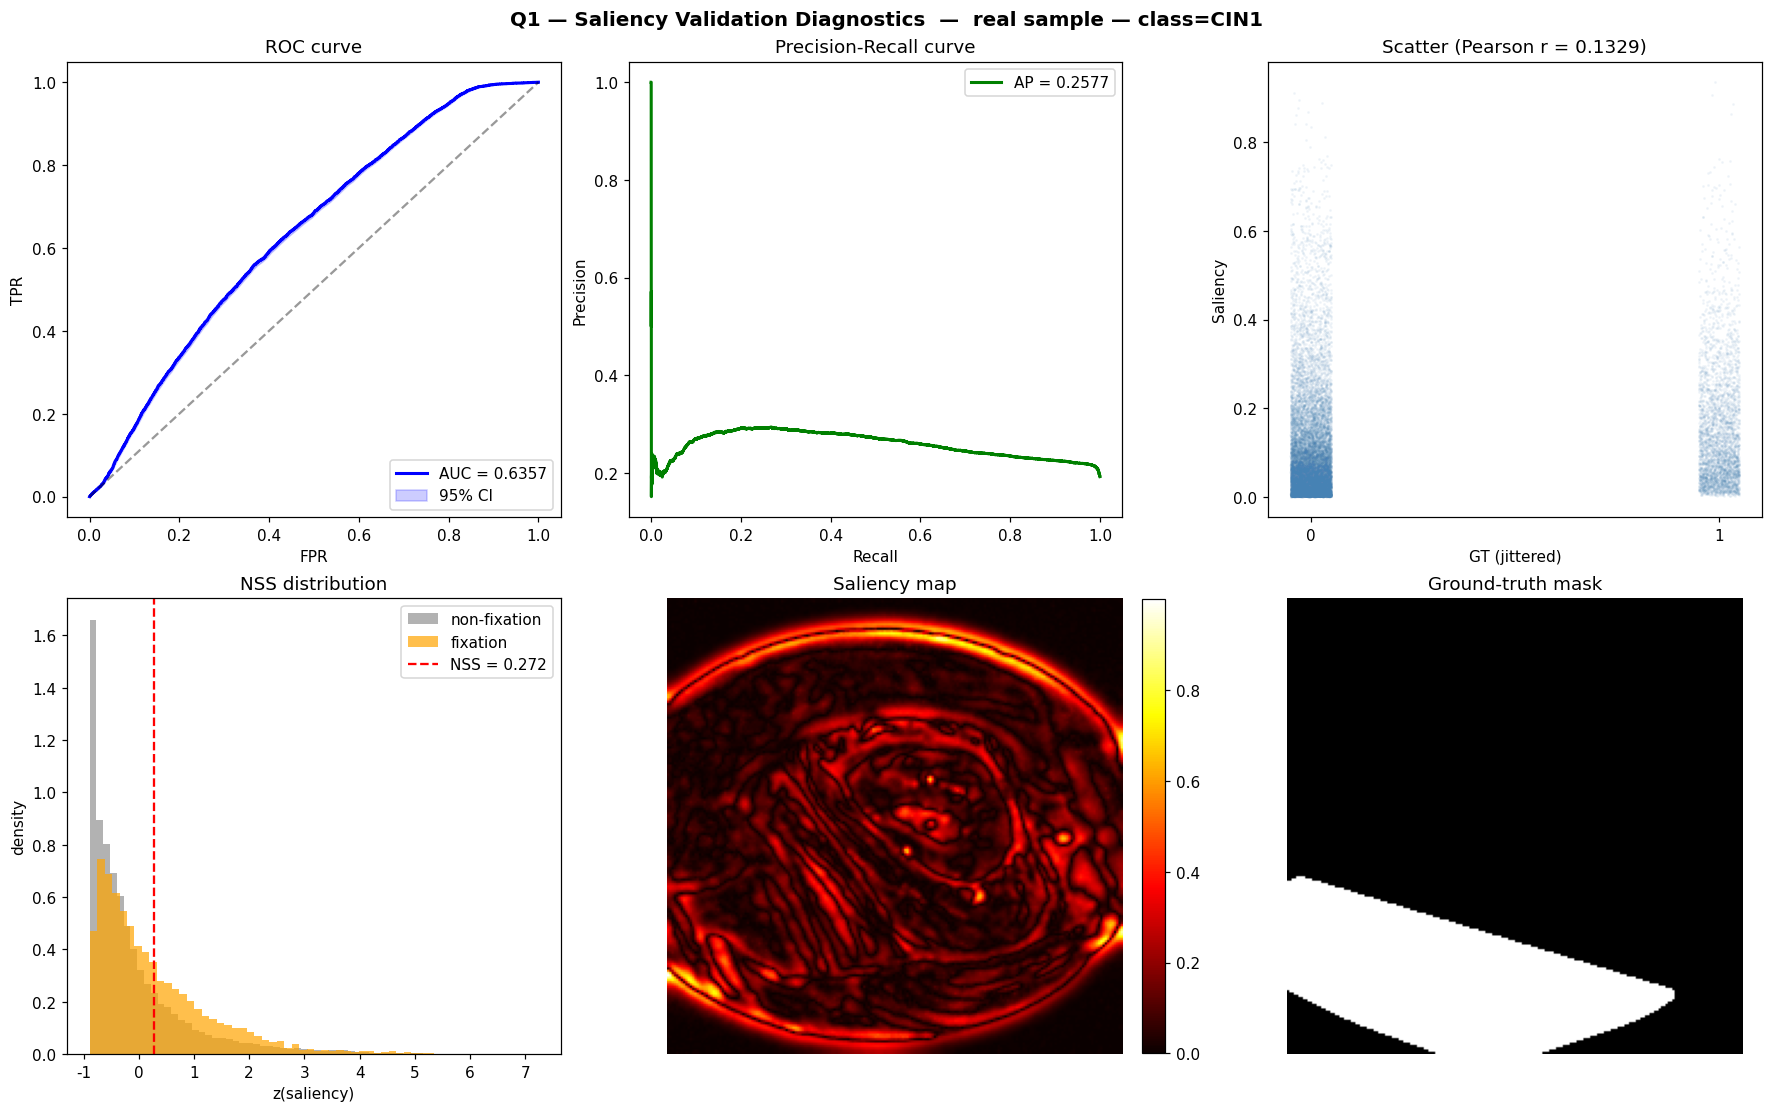

[3/5] Statistical plot ...


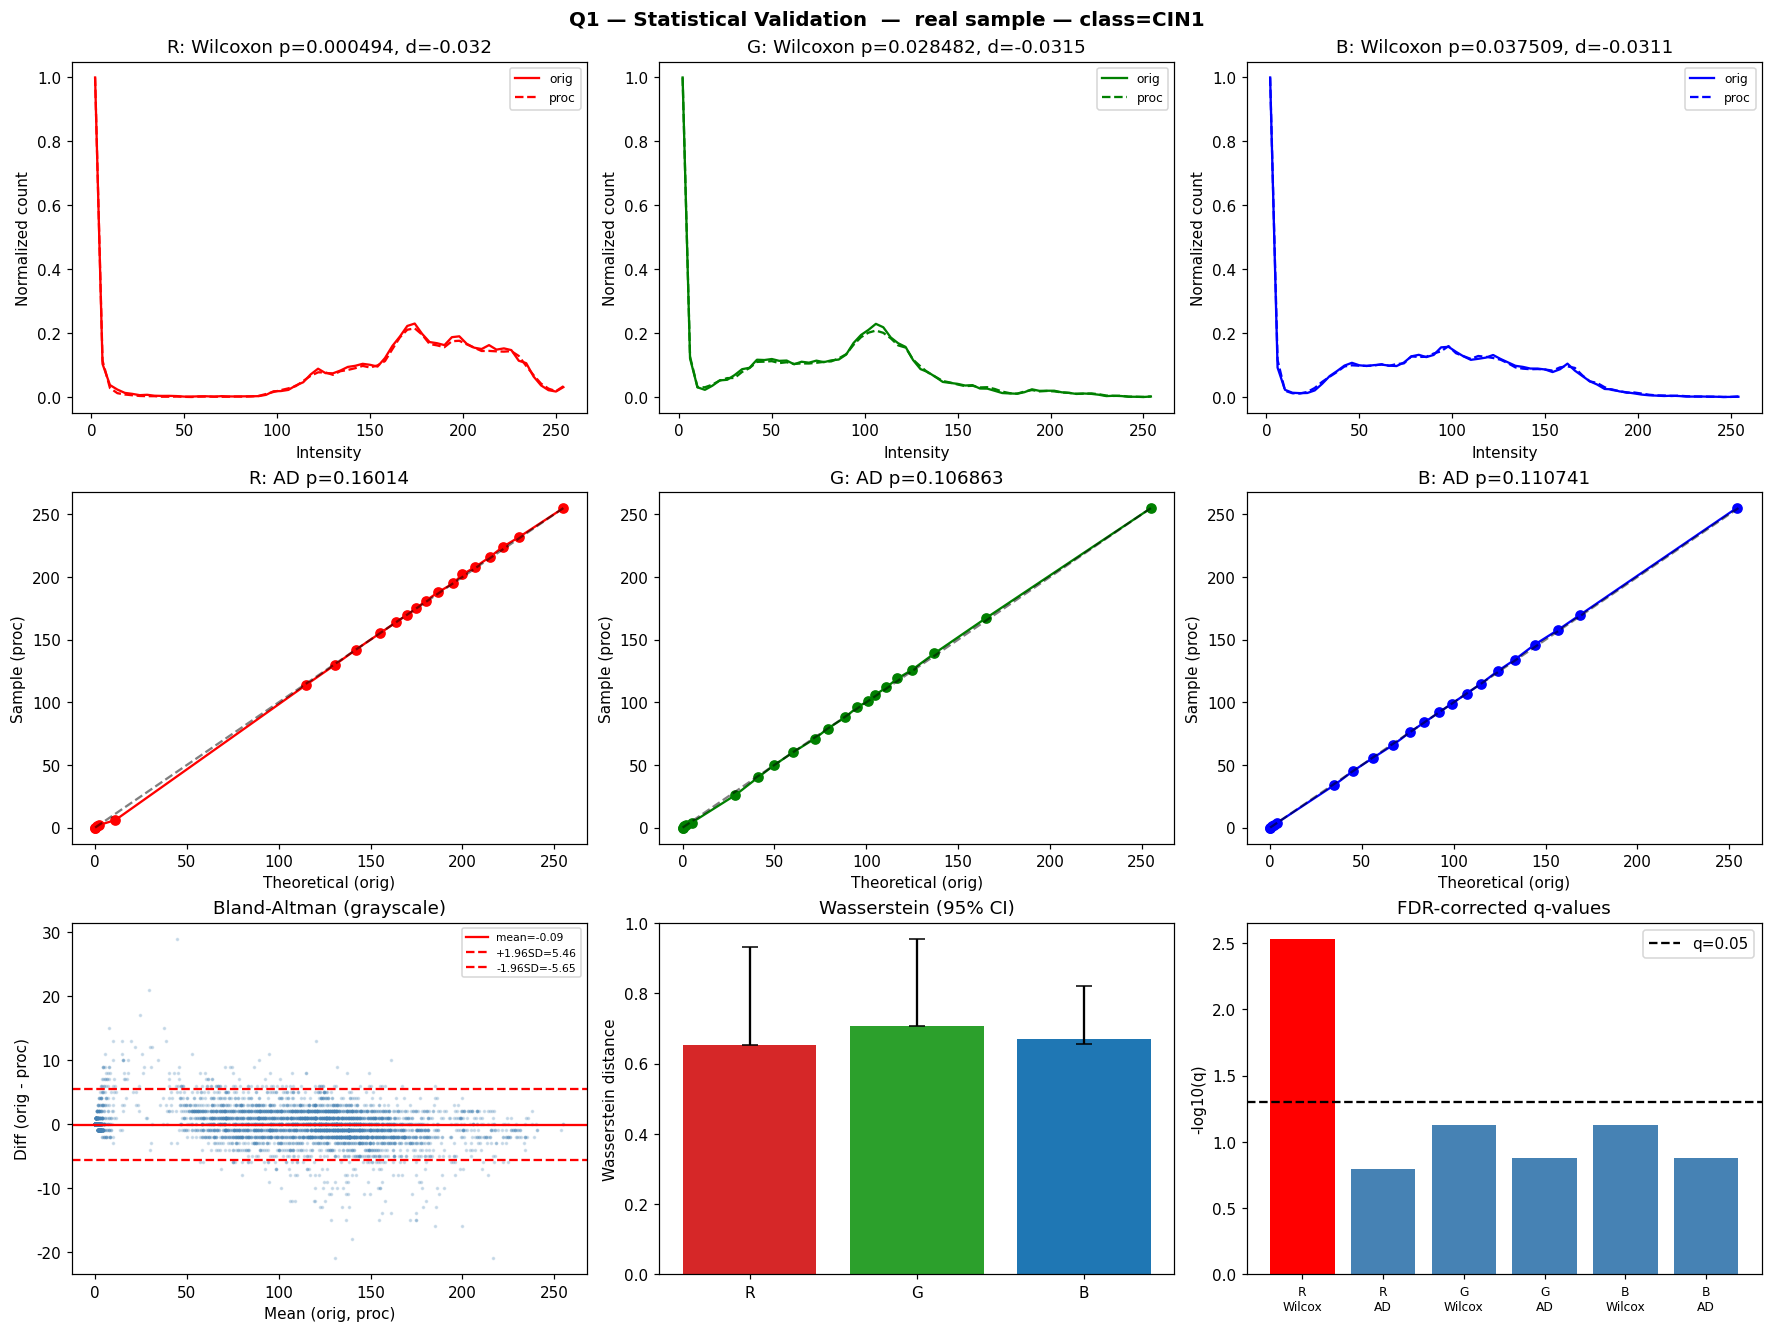

[4/5] ML Impact plot ...


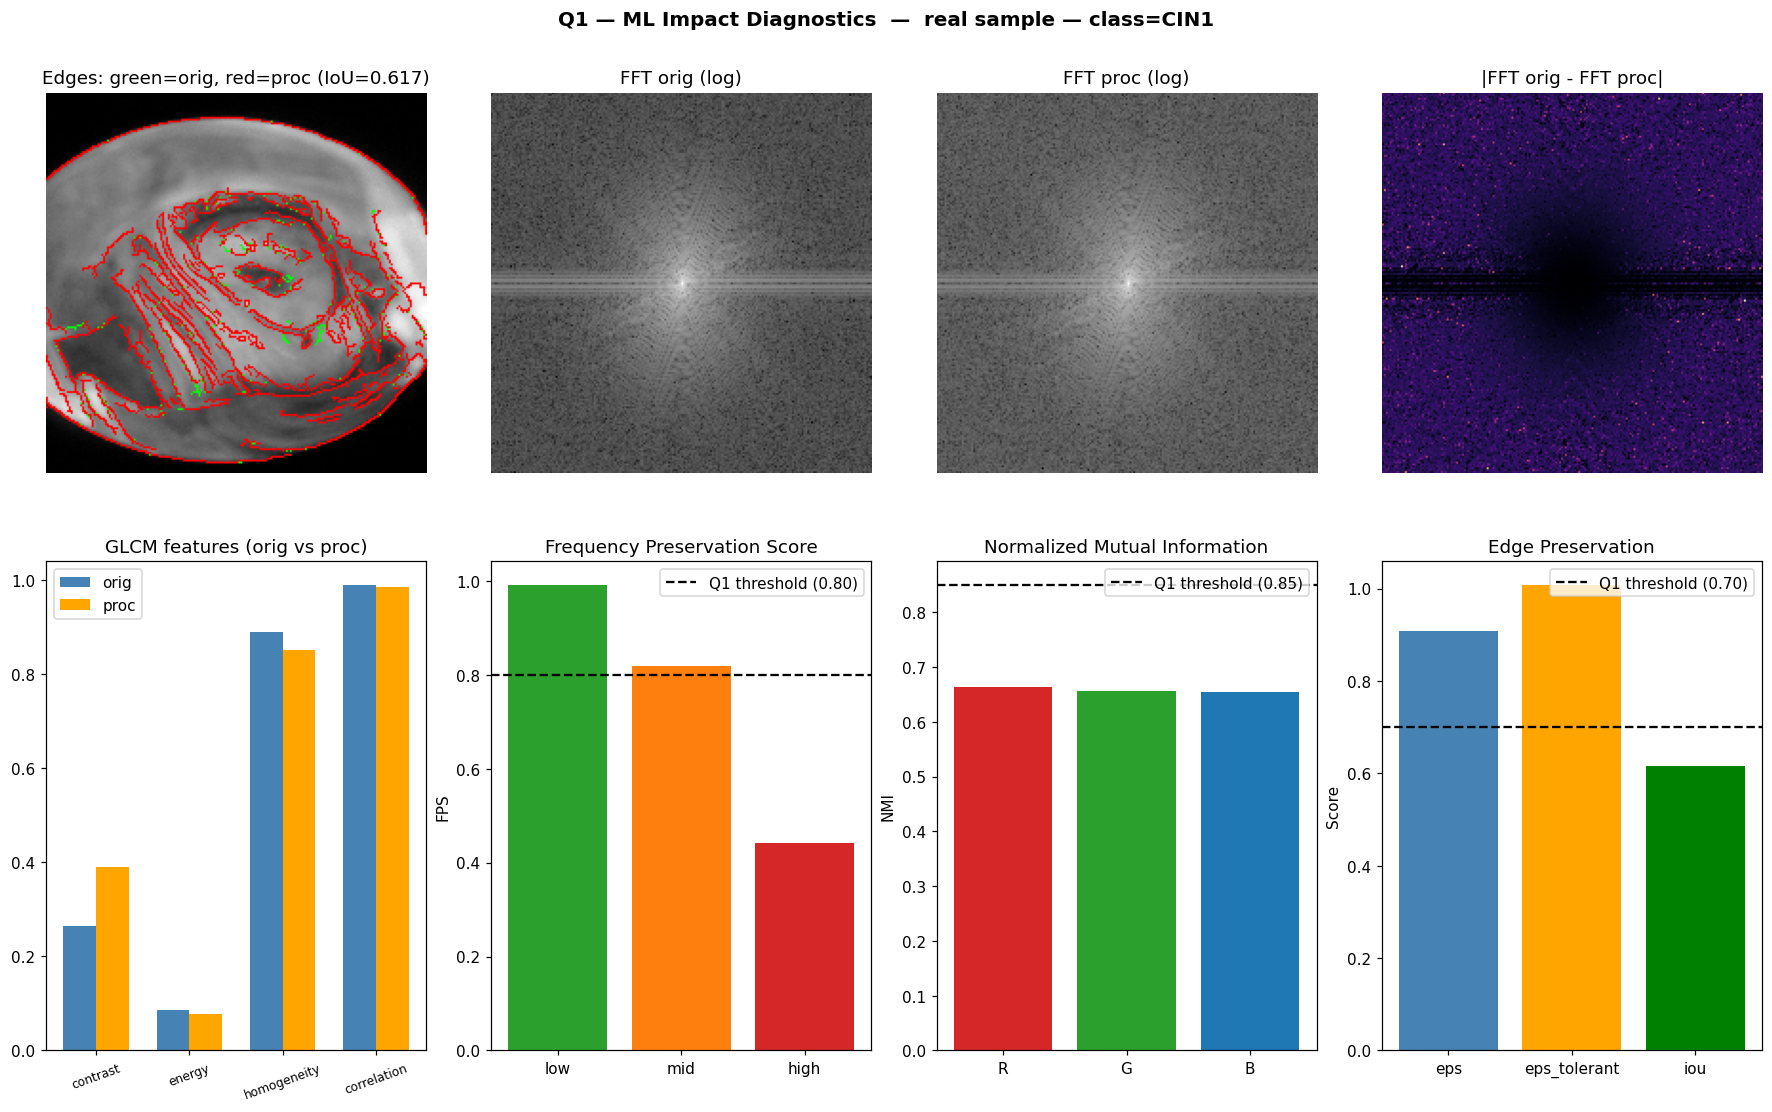

[5/5] Compression plot ...


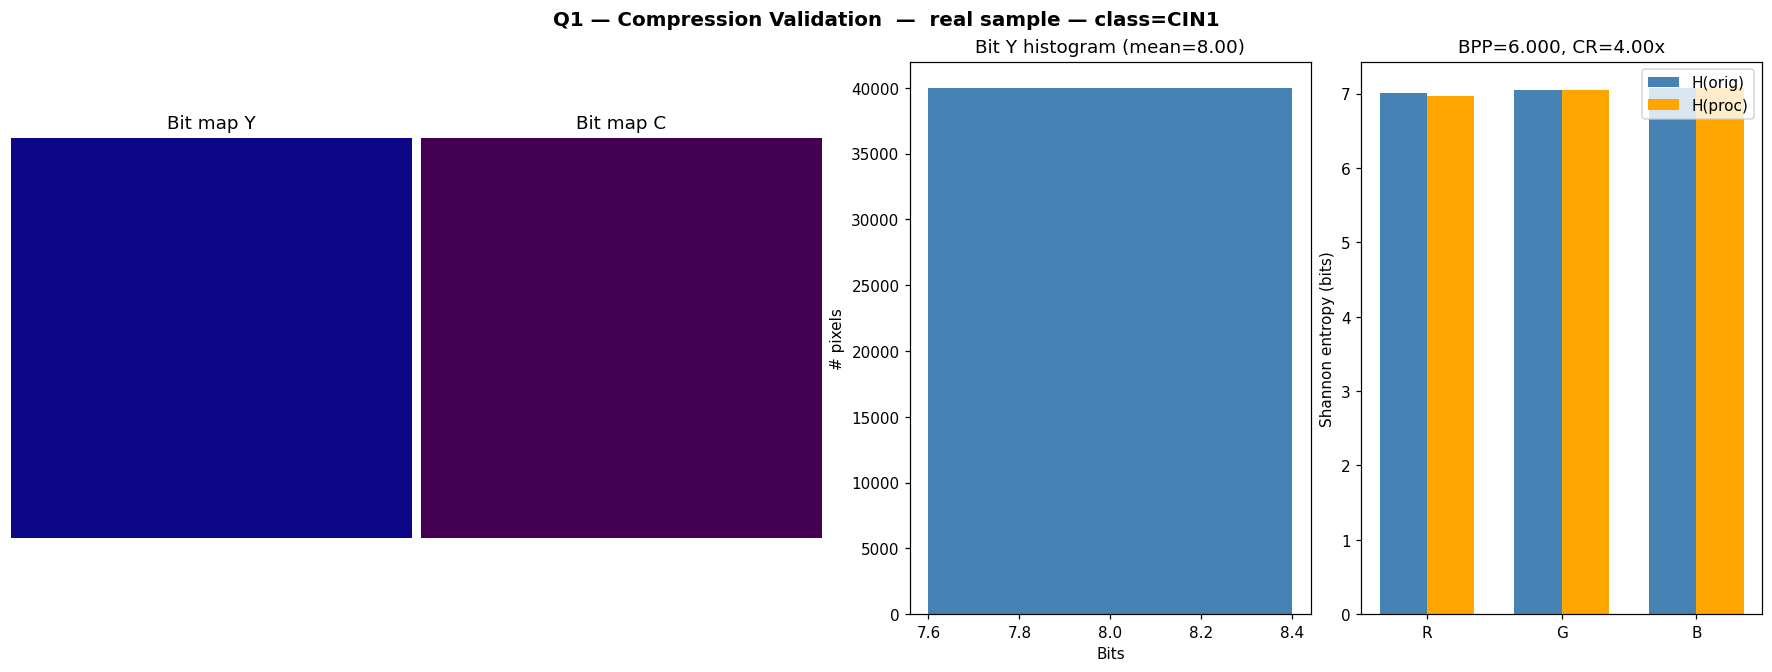

In [17]:
# ============================================================
# Cell — Render all Q1 plots for the single-image sample
# ============================================================
validator.plot_all(_sample_enc, report, title=_title)


## 3.2 — Stratified per-class batch validation

Runs the Q1 suite on a stratified random batch (`VAL_N_PER_CLASS` images
per class) drawn from the real dataset, then renders the master
4×3 dashboard and the Spearman correlation heatmap.


In [18]:
# ============================================================
# Cell — Stratified per-class batch validation (REAL dataset)
# ============================================================
def _encode_fn_from_pair(orig, sharp):
    """encode_fn signature expected by run_stratified_batch:
       img -> encoded dict. We close over the original so the validator
       gets both original + sharpened + ROI masks."""
    def _fn(_img_unused):
        roi = extract_roi(sharp)
        return build_encoded(orig, sharp, roi=roi)
    return _fn

if len(X_original) > 0:
    # Build parallel arrays for run_stratified_batch
    X_orig_batch = X_original
    X_sharp_batch = X_sharpened
    y_batch       = y_labels

    # encode_fn takes the ORIGINAL image and returns the encoded dict
    # (we ignore its argument and use the closure)
    encode_fns = [_encode_fn_from_pair(X_orig_batch[i], X_sharp_batch[i])
                  for i in range(len(X_orig_batch))]

    # run_stratified_batch expects a single encode_fn(img) -> dict, so we
    # adapt by indexing with a small wrapper class
    class _IndexedEncoder:
        def __init__(self, fns):
            self.fns = fns
            self.i = 0
        def __call__(self, img):
            fn = self.fns[self.i % len(self.fns)]
            self.i += 1
            return fn(img)

    # Because run_stratified_batch calls encode_fn on the original image,
    # but our encoded dict needs the *paired* original+sharpened, we
    # instead pre-build the encoded dicts and run the validator directly.
    rng = np.random.RandomState(SEED)
    rows = []
    classes_present = sorted(set(y_batch))
    print(f"Stratified batch: {VAL_N_PER_CLASS} per class × "
          f"{len(classes_present)} classes = "
          f"{VAL_N_PER_CLASS * len(classes_present)} images")
    for cls in classes_present:
        idx = np.where(y_batch == cls)[0]
        idx = rng.choice(idx, size=min(VAL_N_PER_CLASS, len(idx)),
                         replace=False)
        for j, i in enumerate(idx):
            t0 = time.time()
            enc = encoded_all[i]["encoded"]
            rep = validator.validate(enc, ground_truth_mask=None, verbose=False)
            row = _flatten_report(rep)
            row["index"] = int(i)
            row["class"] = str(cls)
            row["runtime_s"] = round(time.time() - t0, 3)
            rows.append(row)
            print(f"  [{cls:>7s}] {j+1:>2d}/{VAL_N_PER_CLASS}  "
                  f"score={rep['final_score']['final']:>6.2f}  "
                  f"grade={rep['final_score']['grade']:<3s}  "
                  f"t={row['runtime_s']:.2f}s")

    df_val = pd.DataFrame(rows)
    print(f"\nBatch done. {len(df_val)} rows.")
    display_cols = ["class", "PSNR", "SSIM", "AUC_ROC", "F_measure",
                    "EPS", "final_score", "grade", "runtime_s"]
    print(df_val[display_cols].to_string(index=False))
else:
    print("No dataset loaded — skipping stratified batch.")
    df_val = pd.DataFrame()


Stratified batch: 5 per class × 4 classes = 20 images
  [   CIN1]  1/5  score= 90.87  grade=A+   t=3.18s
  [   CIN1]  2/5  score= 90.30  grade=A+   t=3.23s
  [   CIN1]  3/5  score= 90.64  grade=A+   t=3.17s
  [   CIN1]  4/5  score= 86.36  grade=A    t=3.38s
  [   CIN1]  5/5  score= 89.12  grade=A    t=3.14s
  [   CIN2]  1/5  score= 90.98  grade=A+   t=2.94s
  [   CIN2]  2/5  score= 90.97  grade=A+   t=3.30s
  [   CIN2]  3/5  score= 82.49  grade=A    t=3.19s
  [   CIN2]  4/5  score= 85.14  grade=A    t=3.15s
  [   CIN2]  5/5  score= 84.73  grade=A    t=3.20s
  [   CIN3]  1/5  score= 89.28  grade=A    t=3.11s
  [   CIN3]  2/5  score= 90.60  grade=A+   t=3.07s
  [   CIN3]  3/5  score= 82.64  grade=A    t=3.24s
  [   CIN3]  4/5  score= 87.63  grade=A    t=3.25s
  [   CIN3]  5/5  score= 84.98  grade=A    t=3.24s
  [ Cancer]  1/5  score= 83.03  grade=A    t=3.26s
  [ Cancer]  2/5  score= 79.87  grade=B    t=3.06s
  [ Cancer]  3/5  score= 81.26  grade=A    t=3.10s
  [ Cancer]  4/5  score= 80.


[Q1] Rendering master validation dashboard ...


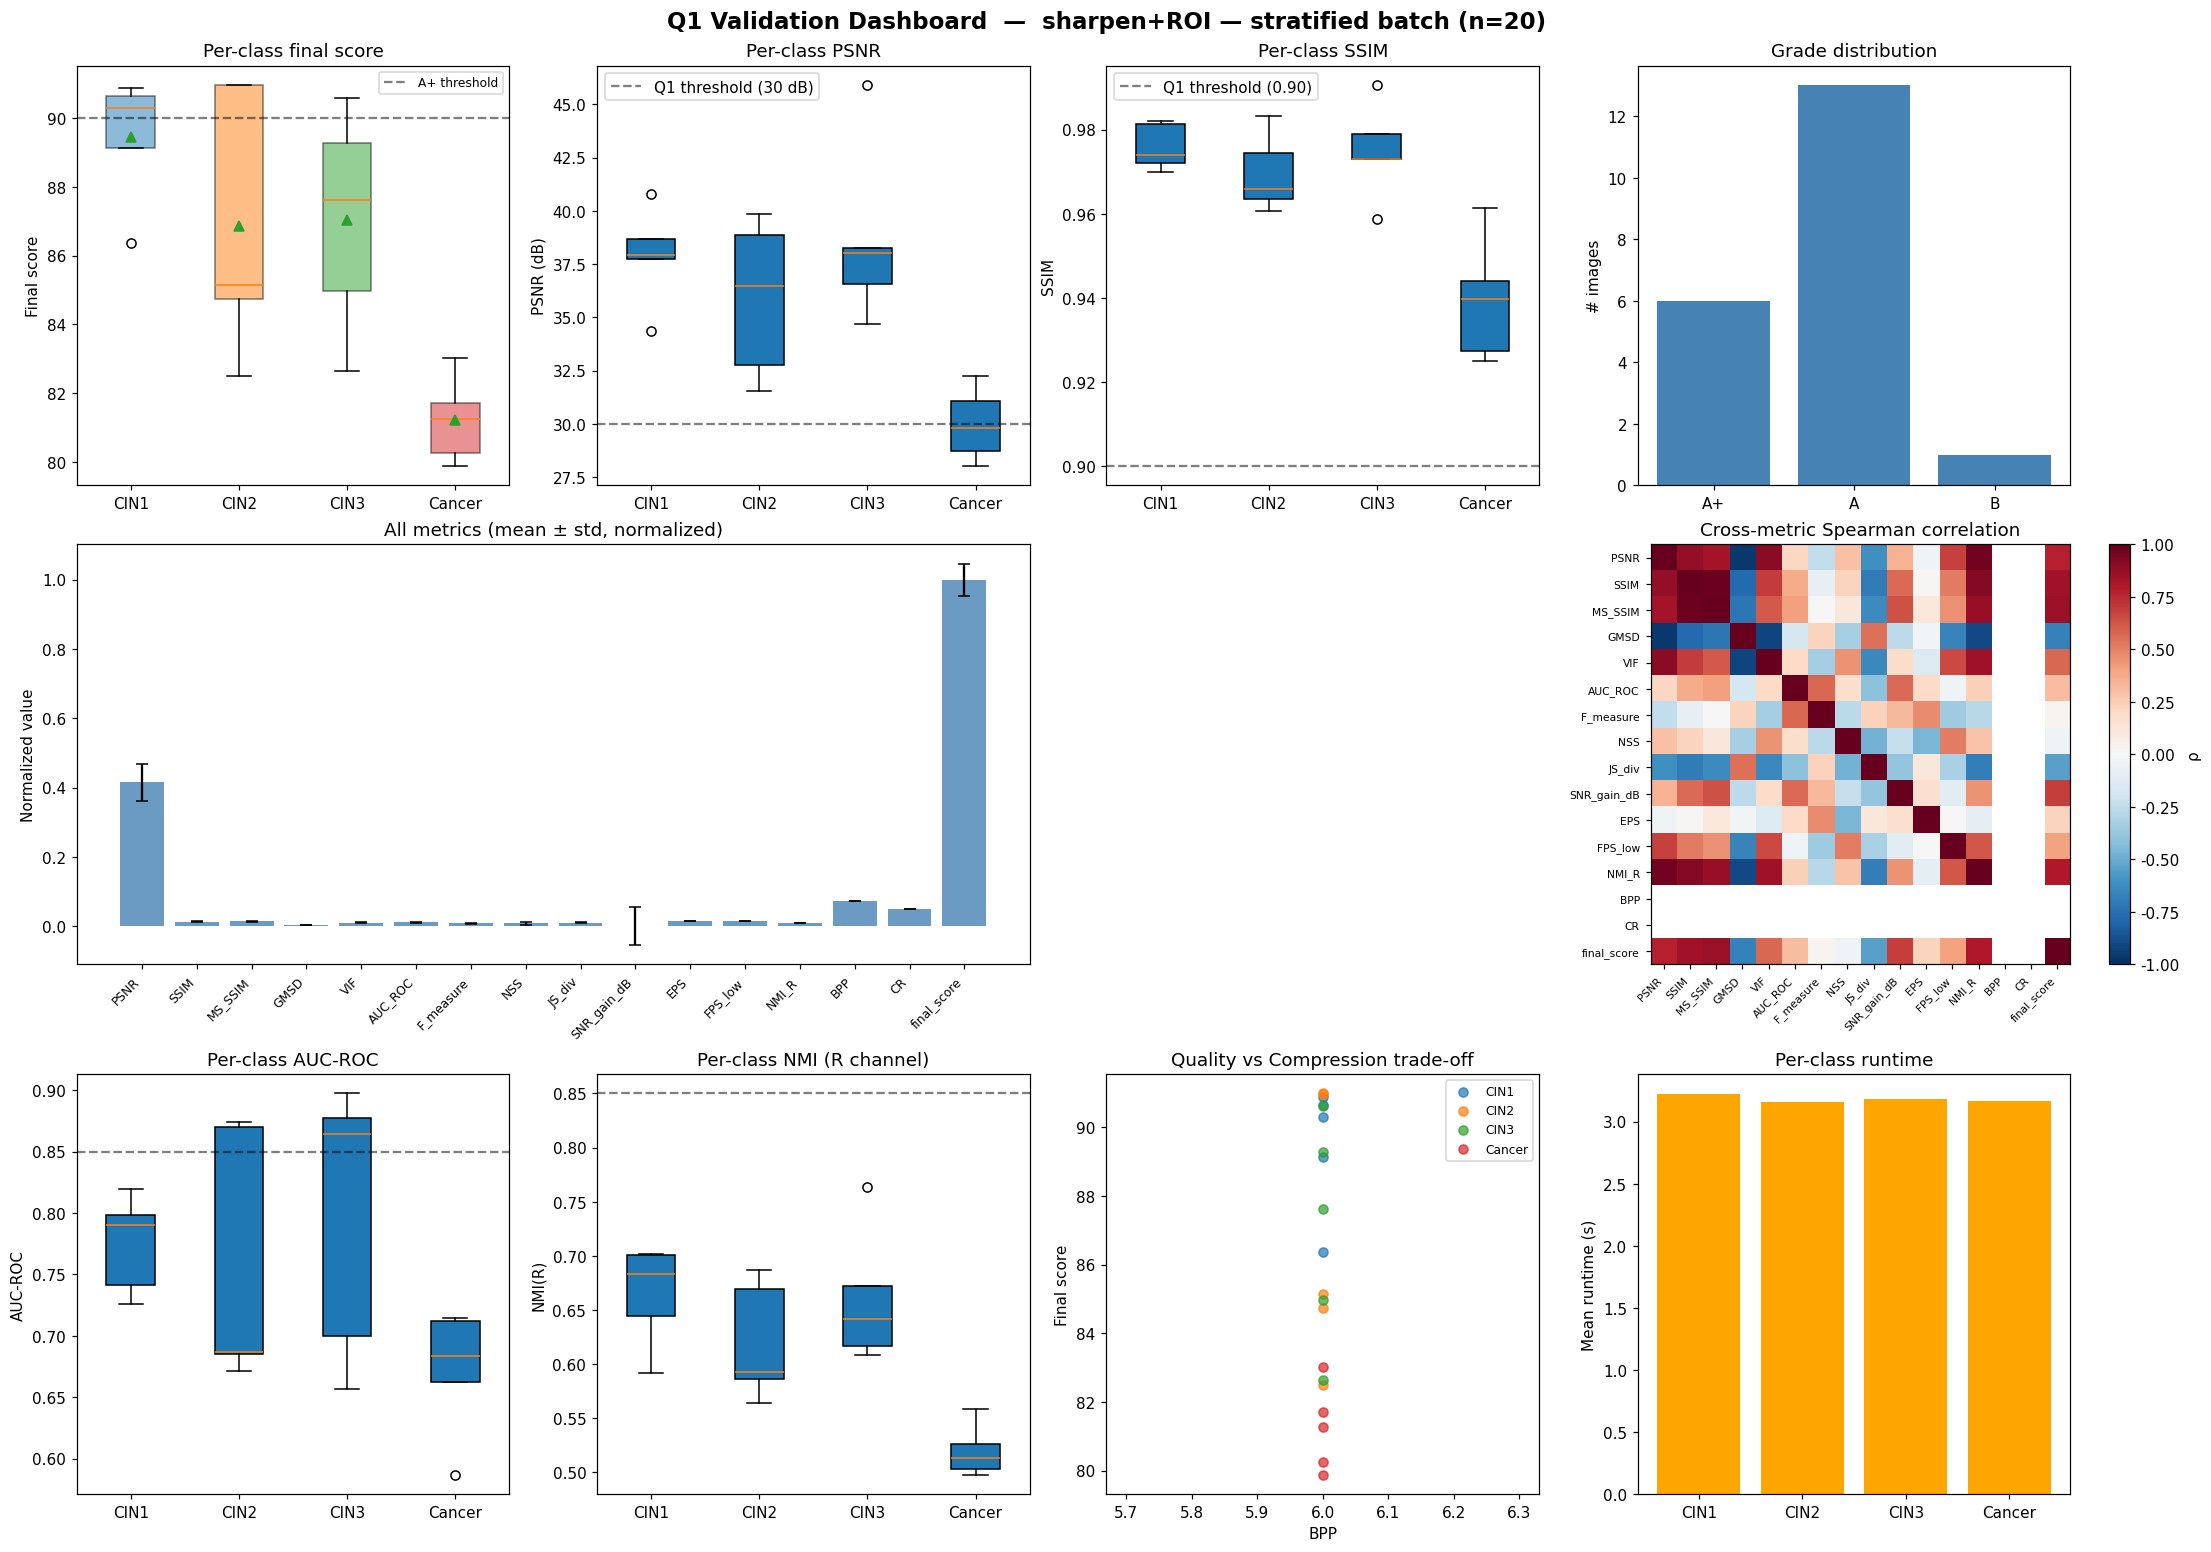


[Q1] Rendering cross-metric Spearman correlation heatmap ...


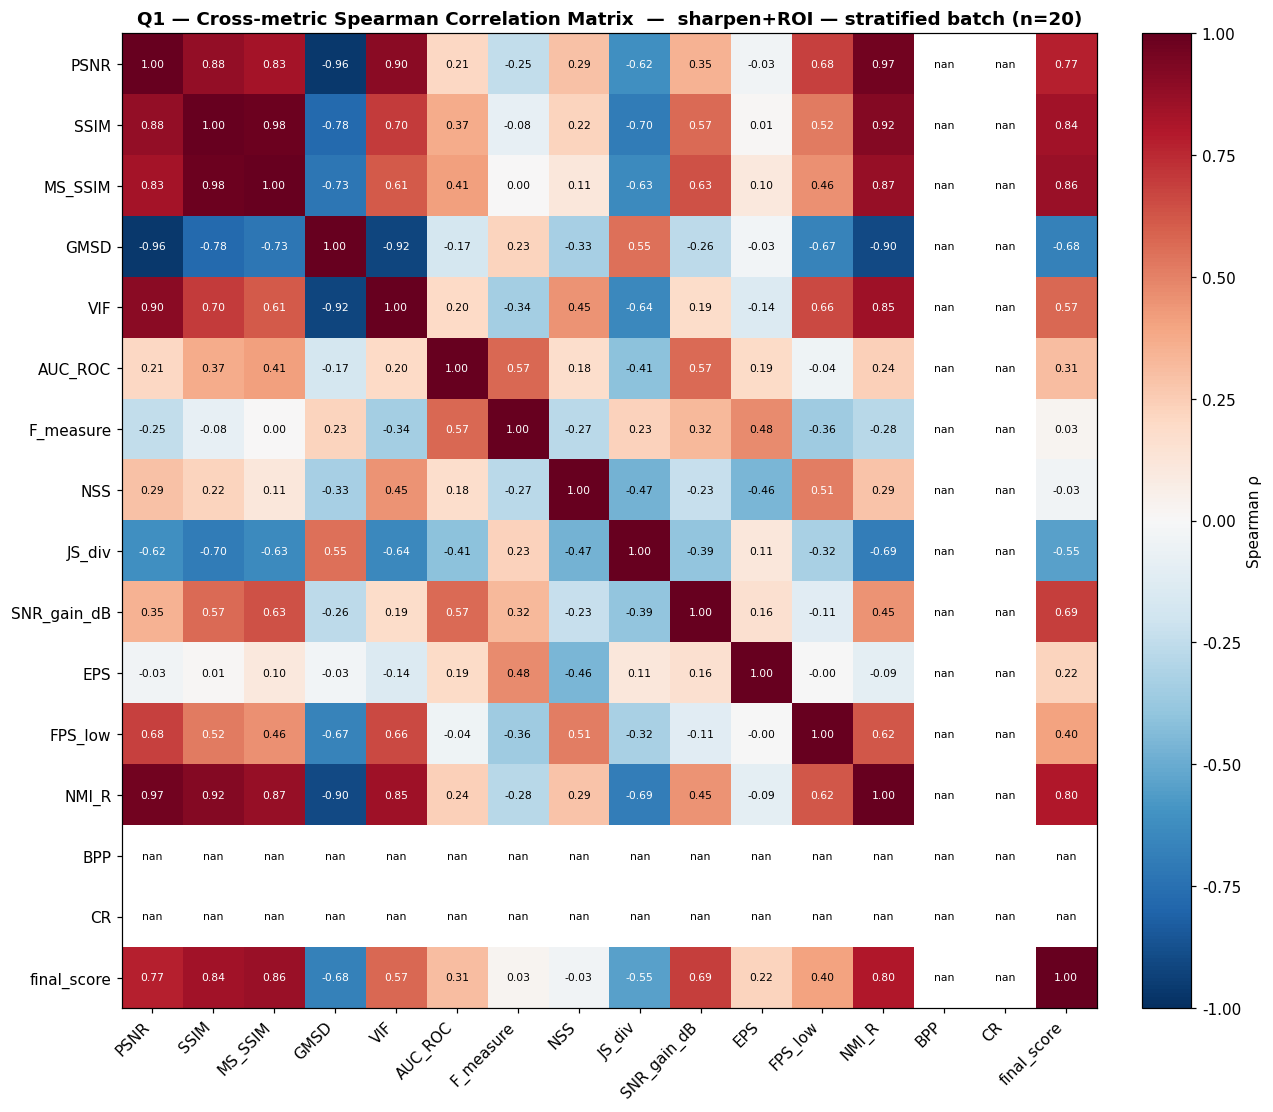


[Q1] Per-image validation table saved to: q1_validation_results_sharpen_roi.csv

[Q1] Per-class summary (mean ± std):
        PSNR_mean  SSIM_mean  MS_SSIM_mean  GMSD_mean  VIF_mean  PSNR_R_mean  PSNR_G_mean  PSNR_B_mean  cohens_d_mean  AUC_ROC_mean  F_measure_mean  NSS_mean  Pearson_CC_mean  JS_div_mean  SNR_gain_dB_mean  bit_corr_mean  mean_bits_mean  coverage_mean  EPS_mean  IoU_edges_mean  FPS_low_mean  FPS_mid_mean  FPS_high_mean  NMI_R_mean  NMI_G_mean  NMI_B_mean  BPP_mean  CR_mean  final_score_mean  runtime_s_mean  PSNR_std  SSIM_std  MS_SSIM_std  GMSD_std  VIF_std  PSNR_R_std  PSNR_G_std  PSNR_B_std  cohens_d_std  AUC_ROC_std  F_measure_std  NSS_std  Pearson_CC_std  JS_div_std  SNR_gain_dB_std  bit_corr_std  mean_bits_std  coverage_std  EPS_std  IoU_edges_std  FPS_low_std  FPS_mid_std  FPS_high_std  NMI_R_std  NMI_G_std  NMI_B_std  BPP_std  CR_std  final_score_std  runtime_s_std
class                                                                                             

In [19]:
# ============================================================
# Cell — Master dashboard + Spearman correlation heatmap
# ============================================================
if len(df_val) > 0:
    print("\n[Q1] Rendering master validation dashboard ...")
    plot_q1_dashboard(df_val,
                      title=f"sharpen+ROI — stratified batch (n={len(df_val)})")

    print("\n[Q1] Rendering cross-metric Spearman correlation heatmap ...")
    plot_correlation_heatmap(df_val,
                             title=f"sharpen+ROI — stratified batch (n={len(df_val)})")

    # Save the batch table to CSV
    csv_path = "q1_validation_results_sharpen_roi.csv"
    df_val.to_csv(csv_path, index=False)
    print(f"\n[Q1] Per-image validation table saved to: {csv_path}")

    # Per-class summary
    print("\n[Q1] Per-class summary (mean ± std):")
    per_class = per_class_summary(df_val)
    print(per_class.to_string())
else:
    print("df_val is empty — nothing to plot.")


In [20]:
# ============================================================
# Cell — Reproducibility metadata
# ============================================================
_meta = reproducibility_metadata()
_meta['notebook_version']  = 'preprocessing_validation_pipeline_sharpen_roi'
_meta['pipeline']          = 'sharpen(unsharp-mask) → ROI(saliency+Otsu+morph+hull) → Q1 validate'
_meta['dataset_root']      = DATASET_ROOT
_meta['classes']           = CLASSES
_meta['n_images_total']    = int(len(X_original))
_meta['batch_size_per_class'] = int(VAL_N_PER_CLASS) if len(df_val) > 0 else 0
_meta['sharpen']           = {'apply': APPLY_SHARPEN,
                               'amount': SHARPEN_AMOUNT,
                               'ksize': SHARPEN_KSIZE}
_meta['roi']               = {'method': ROI_METHOD,
                               'min_area_frac': ROI_MIN_AREA_FRAC,
                               'max_area_frac': ROI_MAX_AREA_FRAC,
                               'morph_kernel': ROI_MORPH_KERNEL,
                               'soft_blur_sigma': ROI_SOFT_BLUR_SIGMA}
_meta['cv_saliency_available'] = bool(HAS_CV_SALIENCY)

print("\n" + "=" * 60)
print("  REPRODUCIBILITY METADATA")
print("=" * 60)
for k, v in _meta.items():
    print(f"  {k:25s}: {v}")
print("=" * 60)

with open("q1_reproducibility_metadata_sharpen_roi.json", "w") as f:
    json.dump(_meta, f, indent=2, default=str)
print("Saved: q1_reproducibility_metadata_sharpen_roi.json")



  REPRODUCIBILITY METADATA
  python_version           : 3.10.20
  platform                 : Windows-10-10.0.26200-SP0
  numpy_version            : 2.2.6
  pandas_version           : 2.3.3
  opencv_version           : 4.11.0
  timestamp_utc            : 2026-07-07 08:51:28 UTC
  random_seed              : 42
  notebook_version         : preprocessing_validation_pipeline_sharpen_roi
  pipeline                 : sharpen(unsharp-mask) → ROI(saliency+Otsu+morph+hull) → Q1 validate
  dataset_root             : Dataset
  classes                  : ['CIN1', 'CIN2', 'CIN3', 'Cancer']
  n_images_total           : 2000
  batch_size_per_class     : 5
  sharpen                  : {'apply': True, 'amount': 0.8, 'ksize': 5}
  roi                      : {'method': 'saliency', 'min_area_frac': 0.02, 'max_area_frac': 0.85, 'morph_kernel': 5, 'soft_blur_sigma': 2.0}
  cv_saliency_available    : False
Saved: q1_reproducibility_metadata_sharpen_roi.json


## How to Adapt This Pipeline

1. **Replace the sharpening** — edit `sharpen()` in Cell 3 (or set
   `APPLY_SHARPEN = False` to disable it entirely) and plug in your own
   preprocessing model. The validator just needs `img_original` and
   `img_processed` of the same shape.
2. **Replace the ROI extractor** — `extract_roi()` in Cell 5 is fully
   self-contained; swap it for a U-Net / Mask R-CNN / thresholding
   method as long as it returns `saliency_map`, `soft_mask`,
   `hard_mask`, `bbox`, `roi_crop`.
3. **Tune the validation batch** — change `VAL_N_PER_CLASS` in Cell 2
   to validate on more/fewer images per class.
4. **Add a ground-truth mask** — if you have lesion annotations, pass
   them as `ground_truth_mask=` to `validator.validate()` for a real
   AUC-ROC / F-measure instead of the pseudo-GT.
5. **Re-run** — every cell is idempotent; just "Run All" after any
   change.

## Outputs

| File | Description |
|---|---|
| `q1_validation_results_sharpen_roi.csv`     | per-image validation metrics (one row per image) |
| `q1_reproducibility_metadata_sharpen_roi.json` | env / seed / config snapshot |
